In [2]:
# CELL 2 — IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              mean_squared_error, mean_absolute_error,
                              confusion_matrix, roc_curve, auc as auc_fn,
                              classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Flatten,
                                      Dense, Dropout, BatchNormalization,
                                      LSTM, Input)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import keras_tuner as kt

print("All imports successful.")
print(f"TensorFlow version : {tf.__version__}")

# ═══════════════════════════════════════════════════════════════
# STEP 1 — DATA COLLECTION
# ═══════════════════════════════════════════════════════════════


All imports successful.
TensorFlow version : 2.19.0


---
## STEP 1 — DATA COLLECTION
---

In [3]:
# CELL 3 — LOAD BTC PRICE DATA
import yfinance as yf

print("Downloading BTC-USD price data...")
df = yf.download('BTC-USD', start='2008-01-01', end='2025-08-15')
df = df.reset_index()
df.columns = [col[0] if isinstance(col, tuple) else col
              for col in df.columns]
df.rename(columns={'Date': 'date'}, inplace=True)
df['Return'] = df['Close'].pct_change()
df['date']   = pd.to_datetime(df['date'])

print(f"BTC price data loaded. Shape: {df.shape}")
print(df.tail(3))


[*********************100%***********************]  1 of 1 completed

BTC price data loaded. Shape: (3985, 7)
           date          Close           High            Low           Open  \
3982 2025-08-12  120172.906250  120302.468750  118228.718750  118717.664062   
3983 2025-08-13  123344.062500  123682.453125  118939.632812  120168.976562   
3984 2025-08-14  118359.578125  124457.117188  117254.882812  123339.398438   

            Volume    Return  
3982   72803657984  0.012141  
3983   90904808795  0.026388  
3984  104055627395 -0.040411  


In [4]:
# CELL 4 — LOAD FINANCIAL NEWS DATA
import kagglehub

path      = kagglehub.dataset_download(
    "pratyushpuri/financial-news-market-events-dataset-2025")
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
assert len(csv_files) > 0, "No CSV found in dataset folder"

news_raw  = pd.read_csv(os.path.join(path, csv_files[0]))
date_col  = [c for c in news_raw.columns if "date"  in c.lower()][0]
text_col  = [c for c in news_raw.columns
             if any(k in c.lower()
                    for k in ["head","title","text","content"])][0]

print(f"News loaded: {news_raw.shape}")
print(f"Date col: {date_col} | Text col: {text_col}")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — DATA PREPROCESSING
# (Missing values, duplicates, encoding, normalization)
# ═══════════════════════════════════════════════════════════════


News loaded: (3024, 12)
Date col: Date | Text col: Headline


---
## STEP 2 — DATA PREPROCESSING
*(Missing values, duplicates, encoding, normalization)*
---

In [5]:
# CELL 5 — TEXTBLOB SENTIMENT + CATEGORY (One-Hot Encoding)
from textblob import TextBlob

print("Running TextBlob sentiment + categorical classification...")
news_data = []
for _, row in news_raw.iterrows():
    title    = str(row.get(text_col, '')).lower()
    date_str = str(row.get(date_col, ''))
    polarity = TextBlob(title).sentiment.polarity

    category = 'other'
    if any(k in title for k in ['bitcoin','crypto','btc','ethereum']):
        category = 'crypto'
    elif any(k in title for k in
             ['inflation','fed','interest rate','gdp','recession']):
        category = 'macro'
    elif any(k in title for k in
             ['war','sanction','iran','israel','russia','ukraine',
              'geopolit']):
        category = 'geopolitics'
    elif any(k in title for k in
             ['crisis','crash','collapse','bankrupt','default']):
        category = 'crisis'

    news_data.append({
        'date'    : date_str,
        'sentiment': polarity,
        'category': category
    })

news_df = pd.DataFrame(news_data)
print(f"TextBlob done. {len(news_df)} articles.")
print(news_df['category'].value_counts())


Running TextBlob sentiment + categorical classification...
TextBlob done. 3024 articles.
category
other          2412
macro           268
geopolitics     229
crypto           58
crisis           57
Name: count, dtype: int64


In [6]:
# CELL 6 — FINBERT SENTIMENT
from transformers import (BertTokenizer, BertForSequenceClassification,
                          pipeline as hf_pipeline)

print("Loading FinBERT...")
model_name = 'yiyanghkust/finbert-tone'
tokenizer  = BertTokenizer.from_pretrained(model_name)
finbert_m  = BertForSequenceClassification.from_pretrained(model_name)
nlp        = hf_pipeline("sentiment-analysis",
                          model=finbert_m, tokenizer=tokenizer)

def get_finbert_score(text):
    if not text or str(text).strip() == '':
        return 0.0
    try:
        r     = nlp(str(text)[:512])[0]
        label = r['label']
        score = r['score']
        return score if label=='Positive' else (-score if label=='Negative' else 0.0)
    except:
        return 0.0

print("Processing 500 headlines with FinBERT...")
finbert_data = []
for art in news_raw.to_dict(orient='records')[:500]:
    finbert_data.append({
        'date'             : str(art.get(date_col, '')),
        'finbert_sentiment': get_finbert_score(str(art.get(text_col,'')))
    })

finbert_df = pd.DataFrame(finbert_data)
print(f"FinBERT done. {len(finbert_df)} records.")


Loading FinBERT...


vocab.txt: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: yiyanghkust/finbert-tone
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

Processing 500 headlines with FinBERT...
FinBERT done. 500 records.


In [7]:
# CELL 7 — MERGE ALL DATA + ONE-HOT ENCODING FOR CATEGORIES
print("Merging sentiment into price data...")

# Daily TextBlob average
daily_tb       = (news_df.groupby('date')['sentiment']
                  .mean().reset_index())
daily_tb['date'] = pd.to_datetime(daily_tb['date'], errors='coerce')
daily_tb.dropna(subset=['date'], inplace=True)

# Daily FinBERT average
daily_fb       = (finbert_df.groupby('date')['finbert_sentiment']
                  .mean().reset_index())
daily_fb['date'] = pd.to_datetime(daily_fb['date'], errors='coerce')
daily_fb.dropna(subset=['date'], inplace=True)

# One-hot pivot for news categories (Requirement 5)
pivot            = (news_df
                    .pivot_table(index='date', columns='category',
                                 values='sentiment', aggfunc='mean')
                    .reset_index().fillna(0))
pivot.columns    = (['date'] +
                    [f'cat_{c}' for c in pivot.columns[1:]])
pivot['date']    = pd.to_datetime(pivot['date'], errors='coerce')
pivot.dropna(subset=['date'], inplace=True)

# Merge into df
for extra, key in [(daily_tb, 'sentiment'),
                   (daily_fb, 'finbert_sentiment')]:
    if key in df.columns:
        df.drop(columns=[key], inplace=True)
    df = pd.merge(df, extra, on='date', how='left')
    df[key].fillna(0, inplace=True)

cat_old = [c for c in df.columns if c.startswith('cat_')]
if cat_old:
    df.drop(columns=cat_old, inplace=True)
df     = pd.merge(df, pivot, on='date', how='left')
cat_cols = [c for c in df.columns if c.startswith('cat_')]
df[cat_cols] = df[cat_cols].fillna(0)

print(f"Merged shape: {df.shape}")


Merging sentiment into price data...
Merged shape: (3985, 14)


In [8]:
# CELL 8 — HANDLE MISSING VALUES + REMOVE DUPLICATES
print("=" * 55)
print("PREPROCESSING: MISSING VALUES & DUPLICATES")
print("=" * 55)

# Remove duplicates
before_dup = len(df)
df.drop_duplicates(subset=['date'], keep='last', inplace=True)
print(f"Duplicates removed: {before_dup - len(df)}")

# Forward-fill price/indicator gaps
price_fill = ['Close','Open','High','Low','Volume','Return']
price_fill = [c for c in price_fill if c in df.columns]
df[price_fill] = df[price_fill].ffill()

# Sentiment: fill with 0 (neutral) for days without news
sent_fill  = ['sentiment','finbert_sentiment'] + cat_cols
df[sent_fill] = df[sent_fill].fillna(0)

# Drop any remaining rows with nulls
before_drop = len(df)
df.dropna(inplace=True)
print(f"Rows removed by dropna: {before_drop - len(df)}")
print(f"Clean shape: {df.shape}")
print(f"Remaining nulls: {df.isnull().sum().sum()}")


PREPROCESSING: MISSING VALUES & DUPLICATES
Duplicates removed: 0
Rows removed by dropna: 1
Clean shape: (3984, 14)
Remaining nulls: 0


REQUIREMENT 1: NULL + OUTLIER ANALYSIS
No null values found — dataset is clean.

Outlier summary (IQR 1.5× rule):
          Feature  Outliers  Outlier %
            Close       211       5.30
             High       204       5.12
              Low       212       5.32
             Open       211       5.30
           Volume        72       1.81
           Return       380       9.54
        sentiment       195       4.89
finbert_sentiment       159       3.99
       cat_crypto        53       1.33
  cat_geopolitics       102       2.56
        cat_macro        56       1.41
        cat_other       194       4.87
IQR capping applied to: []


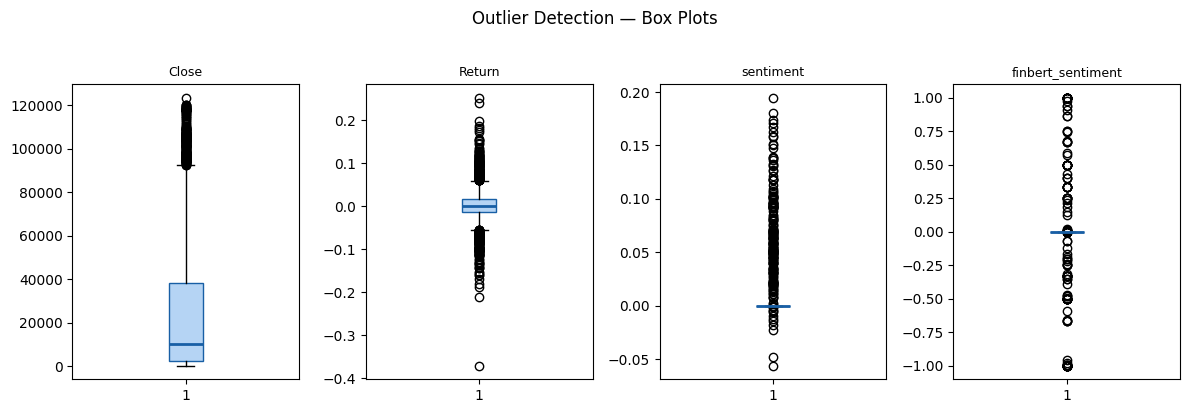

In [9]:
# CELL 9 — NULL VALUES + OUTLIER CHECK (Requirement 1)
print("=" * 55)
print("REQUIREMENT 1: NULL + OUTLIER ANALYSIS")
print("=" * 55)

null_df = pd.DataFrame({
    'Count': df.isnull().sum(),
    '%'    : (df.isnull().sum() / len(df) * 100).round(2)
})
null_df = null_df[null_df['Count'] > 0]
if len(null_df) == 0:
    print("No null values found — dataset is clean.")
else:
    print(null_df)

# IQR outlier scan
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outlier_rows = []
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR    = Q3 - Q1
    n_out  = ((df[col] < Q1-1.5*IQR) | (df[col] > Q3+1.5*IQR)).sum()
    if n_out > 0:
        outlier_rows.append({
            'Feature'  : col,
            'Outliers' : n_out,
            'Outlier %': round(n_out/len(df)*100, 2)
        })

print("\nOutlier summary (IQR 1.5× rule):")
print(pd.DataFrame(outlier_rows).to_string(index=False))

# IQR capping
cap_cols = ['Volatility','RSI','MACD','Momentum','Price_Change']
cap_cols = [c for c in cap_cols if c in df.columns]
for col in cap_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR    = Q3 - Q1
    df[col]= np.clip(df[col], Q1-1.5*IQR, Q3+1.5*IQR)
print(f"IQR capping applied to: {cap_cols}")

# Box plots
box_cols = ['Close','Return','RSI','MACD',
            'Volatility','sentiment','finbert_sentiment']
box_cols = [c for c in box_cols if c in df.columns]

fig, axes = plt.subplots(1, len(box_cols),
                          figsize=(3*len(box_cols), 4))
for i, col in enumerate(box_cols):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='#B5D4F4',color='#185FA5'),
                    medianprops=dict(color='#185FA5',linewidth=2))
    axes[i].set_title(col, fontsize=9)
plt.suptitle('Outlier Detection — Box Plots', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('/kaggle/working/01_outlier_boxplots.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ═══════════════════════════════════════════════════════════════
# STEP 3 — EXPLORATORY DATA ANALYSIS (EDA)
# (Requirement 2)
# ═══════════════════════════════════════════════════════════════


---
## STEP 3 — EXPLORATORY DATA ANALYSIS (EDA)
---

REQUIREMENT 2: EDA VISUALIZATIONS


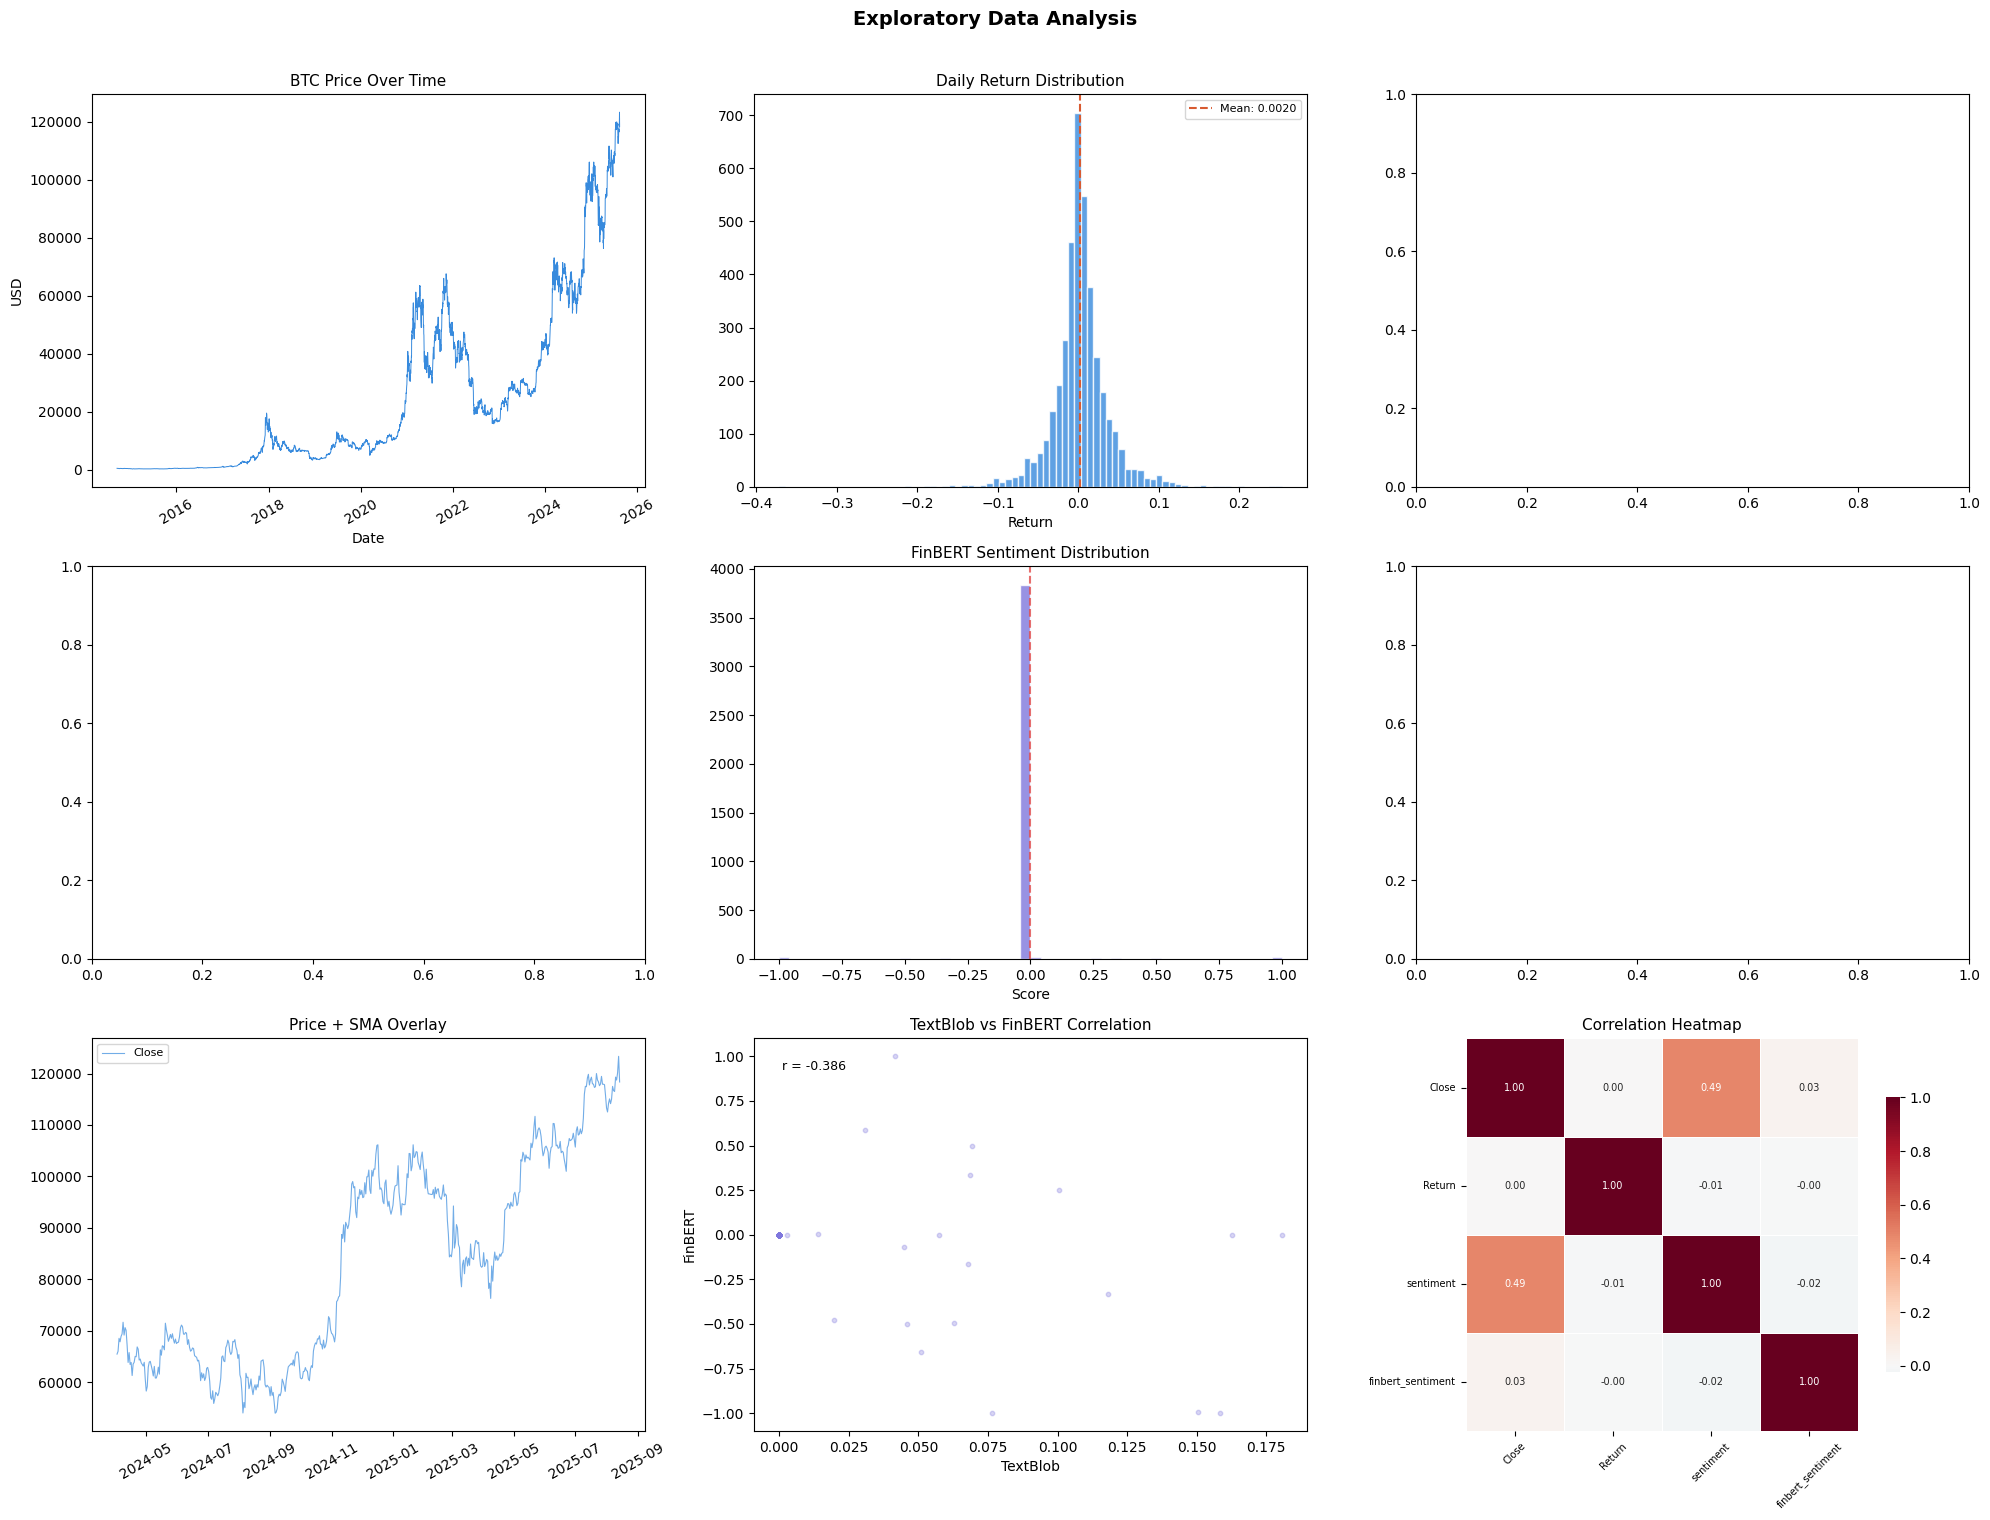

In [10]:
# CELL 10 — FULL EDA VISUALIZATIONS
print("=" * 50)
print("REQUIREMENT 2: EDA VISUALIZATIONS")
print("=" * 50)

fig = plt.figure(figsize=(20, 15))

ax1 = fig.add_subplot(3, 3, 1)
ax1.plot(df['date'], df['Close'],
         color='#378ADD', linewidth=0.7)
ax1.set_title('BTC Price Over Time', fontsize=11)
ax1.set_xlabel('Date'); ax1.set_ylabel('USD')
ax1.tick_params(axis='x', rotation=30)

ax2 = fig.add_subplot(3, 3, 2)
ret = df['Return'].dropna()
ax2.hist(ret, bins=80, color='#378ADD', edgecolor='white', alpha=0.8)
ax2.axvline(ret.mean(), color='#D85A30', linestyle='--', linewidth=1.5,
            label=f'Mean: {ret.mean():.4f}')
ax2.set_title('Daily Return Distribution', fontsize=11)
ax2.set_xlabel('Return'); ax2.legend(fontsize=8)

ax3 = fig.add_subplot(3, 3, 3)
if 'RSI' in df.columns:
    ax3.hist(df['RSI'].dropna(), bins=40,
             color='#1D9E75', edgecolor='white', alpha=0.8)
    ax3.axvline(30, color='#E24B4A', linestyle='--',
                alpha=0.8, label='Oversold')
    ax3.axvline(70, color='#BA7517', linestyle='--',
                alpha=0.8, label='Overbought')
    ax3.set_title('RSI Distribution', fontsize=11)
    ax3.legend(fontsize=8)

ax4 = fig.add_subplot(3, 3, 4)
if 'Volatility' in df.columns:
    ax4.plot(df['date'], df['Volatility'],
             color='#D85A30', linewidth=0.6, alpha=0.8)
    ax4.set_title('Rolling Volatility', fontsize=11)
    ax4.tick_params(axis='x', rotation=30)

ax5 = fig.add_subplot(3, 3, 5)
ax5.hist(df['finbert_sentiment'].dropna(), bins=50,
         color='#7F77DD', edgecolor='white', alpha=0.8)
ax5.axvline(0, color='#E24B4A', linestyle='--', alpha=0.8)
ax5.set_title('FinBERT Sentiment Distribution', fontsize=11)
ax5.set_xlabel('Score')

ax6 = fig.add_subplot(3, 3, 6)
if 'Target' in df.columns:
    counts = df['Target'].value_counts().sort_index()
    bars   = ax6.bar(['Down/Flat (0)','Up >1% (1)'],
                     counts.values,
                     color=['#E24B4A','#639922'],
                     edgecolor='white')
    for bar, val in zip(bars, counts.values):
        ax6.text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+5,
                 f'{val}\n({val/len(df)*100:.1f}%)',
                 ha='center', fontsize=9)
    ax6.set_title('Target Class Distribution', fontsize=11)

ax7 = fig.add_subplot(3, 3, 7)
s = df.tail(500)
ax7.plot(s['date'], s['Close'], color='#378ADD',
         linewidth=0.8, label='Close', alpha=0.7)
if 'SMA_10' in df.columns:
    ax7.plot(s['date'], s['SMA_10'], color='#D85A30',
             linewidth=1.2, label='SMA 10')
if 'SMA_20' in df.columns:
    ax7.plot(s['date'], s['SMA_20'], color='#1D9E75',
             linewidth=1.2, label='SMA 20')
ax7.set_title('Price + SMA Overlay', fontsize=11)
ax7.legend(fontsize=8)
ax7.tick_params(axis='x', rotation=30)

ax8 = fig.add_subplot(3, 3, 8)
samp = df[['finbert_sentiment','sentiment']].dropna().sample(
    min(500, len(df)), random_state=42)
ax8.scatter(samp['sentiment'], samp['finbert_sentiment'],
            alpha=0.3, color='#7F77DD', s=10)
corr_val = samp.corr().iloc[0, 1]
ax8.text(0.05, 0.92, f'r = {corr_val:.3f}',
         transform=ax8.transAxes, fontsize=9)
ax8.set_xlabel('TextBlob'); ax8.set_ylabel('FinBERT')
ax8.set_title('TextBlob vs FinBERT Correlation', fontsize=11)

ax9 = fig.add_subplot(3, 3, 9)
corr_cols = ['Close','Return','RSI','MACD','Volatility',
             'SMA_10','Momentum','sentiment',
             'finbert_sentiment','Target']
corr_cols = [c for c in corr_cols if c in df.columns]
sns.heatmap(df[corr_cols].corr(), ax=ax9, annot=True,
            fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.4,
            annot_kws={'size':7},
            cbar_kws={'shrink':0.7})
ax9.set_title('Correlation Heatmap', fontsize=11)
ax9.tick_params(axis='x', rotation=45, labelsize=7)
ax9.tick_params(axis='y', rotation=0,  labelsize=7)

plt.suptitle('Exploratory Data Analysis',
             fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/02_eda.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ═══════════════════════════════════════════════════════════════
# STEP 4 — FEATURE ENGINEERING & SELECTION
# ═══════════════════════════════════════════════════════════════


---
## STEP 4 — FEATURE ENGINEERING & SELECTION
---

In [11]:
# CELL 11 — TECHNICAL INDICATORS + NOVEL FEATURES
print("Engineering features...")

df['SMA_10']       = df['Close'].rolling(10).mean()
df['SMA_20']       = df['Close'].rolling(20).mean()
df['EMA_10']       = df['Close'].ewm(span=10, adjust=False).mean()
df['Volatility']   = df['Return'].rolling(10).std()

delta = df['Close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
df['RSI']          = 100 - (100 / (1 + gain/loss.replace(0, np.nan)))
df['MACD']         = (df['Close'].ewm(span=12,adjust=False).mean() -
                      df['Close'].ewm(span=26,adjust=False).mean())
df['Momentum']     = df['Close'] - df['Close'].shift(4)
df['Price_Change'] = df['Close'].diff()
df['Lag_1']        = df['Return'].shift(1)
df['Lag_2']        = df['Return'].shift(2)
df['Lag_3']        = df['Return'].shift(3)
df['Log_Return']   = np.log(df['Close'] / df['Close'].shift(1))

df['sentiment_lag1']     = df['sentiment'].shift(1)
df['sentiment_lag2']     = df['sentiment'].shift(2)
df['finbert_lag1']       = df['finbert_sentiment'].shift(1)
df['finbert_lag2']       = df['finbert_sentiment'].shift(2)

# Novel engineered features
df['sent_vol_interaction'] = df['finbert_sentiment'] * df['Volatility']
df['sent_momentum']        = df['finbert_sentiment'] * df['Momentum']
df['sent_change']          = df['finbert_sentiment'].diff()
df['Short_Vol_Shock']      = (df['Volatility'] /
                              df['Volatility'].rolling(3).mean())
df['Sentiment_Velocity']   = (df['finbert_sentiment']
                              .rolling(3).mean().diff())

df[['sentiment_lag1','sentiment_lag2',
    'finbert_lag1','finbert_lag2',
    'sent_vol_interaction','sent_momentum','sent_change',
    'Short_Vol_Shock','Sentiment_Velocity']] = \
    df[['sentiment_lag1','sentiment_lag2',
        'finbert_lag1','finbert_lag2',
        'sent_vol_interaction','sent_momentum','sent_change',
        'Short_Vol_Shock','Sentiment_Velocity']].fillna(0)

df.dropna(inplace=True)
print(f"After feature engineering: {df.shape}")


Engineering features...
After feature engineering: (3965, 35)


In [12]:
# GPR INTEGRATION — Caldara & Iacoviello Geopolitical Risk Index
# Place this cell AFTER technical indicators, BEFORE target variable
print("=" * 55)
print("NOVELTY: GPR INDEX INTEGRATION")
print("Caldara & Iacoviello (2022) — American Economic Review")
print("=" * 55)

import pandas as pd
import numpy as np
import os

# ── Step 1: Find and load GPR file ───────────────────────────
# Scan all input folders for the GPR file
gpr_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for fname in files:
        if 'gpr' in fname.lower() and (
                fname.endswith('.xls') or
                fname.endswith('.xlsx') or
                fname.endswith('.csv')):
            gpr_path = os.path.join(root, fname)
            print(f"GPR file found: {gpr_path}")
            break

if gpr_path is None:
    print("ERROR: GPR file not found.")
    print("Please upload data_gpr_daily_recent.xls to Kaggle.")
    print("Download from: https://www.matteoiacoviello.com/gpr.htm")
else:
    # ── Step 2: Load and clean GPR data ──────────────────────
    if gpr_path.endswith('.csv'):
        gpr_raw = pd.read_csv(gpr_path)
    else:
        gpr_raw = pd.read_excel(gpr_path)

    # Standardise column names
    gpr_raw.columns = [str(c).strip().upper()
                       for c in gpr_raw.columns]
    print(f"GPR columns: {gpr_raw.columns.tolist()}")
    print(f"GPR shape  : {gpr_raw.shape}")
    print(gpr_raw.head(3))

    # ── Step 3: Parse date ───────────────────────────────────
    # GPR date column is usually 'DATE' or 'date'
    date_col_gpr = 'DATE' if 'DATE' in gpr_raw.columns else 'date'.upper()
    gpr_raw[date_col_gpr] = pd.to_datetime(
        gpr_raw[date_col_gpr], errors='coerce')
    gpr_raw.dropna(subset=[date_col_gpr], inplace=True)
    gpr_raw.set_index(date_col_gpr, inplace=True)

    # ── Step 4: Select relevant GPR columns ──────────────────
    # GPRD  = overall daily GPR score
    # GPRD_ACT    = actual conflict events (military strikes etc)
    # GPRD_THREAT = diplomatic tensions and warnings
    # GPRD_MA7    = 7-day moving average (smoothed)
    # GPRD_MA30   = 30-day moving average (long-term trend)
    gpr_cols_wanted = ['GPRD', 'GPRD_ACT', 'GPRD_THREAT',
                       'GPRD_MA7', 'GPRD_MA30']
    gpr_cols_avail  = [c for c in gpr_cols_wanted
                       if c in gpr_raw.columns]
    print(f"\nGPR columns available: {gpr_cols_avail}")

    gpr_df = gpr_raw[gpr_cols_avail].copy()

    # ── Step 5: Engineer additional GPR features ─────────────
    if 'GPRD' in gpr_df.columns:
        # Day-over-day change in GPR (spike detection)
        gpr_df['GPRD_CHANGE']  = gpr_df['GPRD'].pct_change()

        # Spike indicator: top 10% GPR days = major geopolitical event
        gpr_spike_threshold    = gpr_df['GPRD'].quantile(0.90)
        gpr_df['GPRD_SPIKE']   = (
            gpr_df['GPRD'] > gpr_spike_threshold).astype(int)

        # Lagged GPR — markets react to yesterday's geopolitical news
        gpr_df['GPRD_LAG1']    = gpr_df['GPRD'].shift(1)
        gpr_df['GPRD_LAG3']    = gpr_df['GPRD'].shift(3)
        gpr_df['GPRD_LAG7']    = gpr_df['GPRD'].shift(7)

        # GPR regime: HIGH (above median) vs LOW (below median)
        gpr_median             = gpr_df['GPRD'].median()
        gpr_df['GPRD_REGIME']  = (
            gpr_df['GPRD'] > gpr_median).astype(int)

        print(f"\nGPR spike threshold (90th pct): {gpr_spike_threshold:.2f}")
        print(f"GPR median (regime boundary)  : {gpr_median:.2f}")
        print(f"High GPR days                 : "
              f"{gpr_df['GPRD_REGIME'].sum()}")

    print(f"\nGPR engineered columns: {gpr_df.columns.tolist()}")
gpr_fill_cols = gpr_df.columns.tolist()

# --- IMPROVED STEP 6: Merge GPR into main df ---
# Wrap this in a check to ensure gpr_df exists
if 'gpr_df' in locals():
    gpr_fill_cols = gpr_df.columns.tolist()

    # 2. Check if 'df' exists; if not, try to catch if you named it 'data'
    if 'df' not in locals() and 'data' in locals():
        df = data 
        print("Note: 'df' was not found, using 'data' as the main DataFrame.")

    if 'df' in locals():
        # Ensure date column is datetime format for the merge
        df['date'] = pd.to_datetime(df['date'])

        # Merge GPR data onto the main Bitcoin DataFrame
        df = df.merge(gpr_df, left_on='date', right_index=True, how='left')

        # Forward fill: carries GPR values through weekends (BTC trades 24/7, GPR is Daily/Business)
        df[gpr_fill_cols] = df[gpr_fill_cols].ffill()

        # Backward fill: handles any missing values at the very start of the series
        df[gpr_fill_cols] = df[gpr_fill_cols].bfill()

        # 3. CRITICAL: Handle Infinity and remaining NaNs
        # Replaces 'inf' (often from pct_change) with NaN so they can be dropped
        df.replace([np.inf, -np.inf], np.nan, inplace=True)

        # Drop any rows that still have NaNs (ensures scaler won't crash)
        df.dropna(inplace=True)

        print(f"Final shape after GPR merge and INF/NaN cleaning: {df.shape}")
    else:
        print("ERROR: Main DataFrame 'df' (or 'data') not found. Please run your data loading cell.")
else:
    print("Skipping Merge: GPR data was not loaded.")

NOVELTY: GPR INDEX INTEGRATION
Caldara & Iacoviello (2022) — American Economic Review
GPR file found: /kaggle/input/datasets/hasibulhasanrifat/last-data/data_gpr_daily_recent (1).xls
GPR columns: ['DAY', 'N10D', 'GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'DATE', 'GPRD_MA30', 'GPRD_MA7', 'EVENT', 'VAR_NAME', 'VAR_LABEL']
GPR shape  : (15099, 11)
        DAY  N10D        GPRD    GPRD_ACT  GPRD_THREAT       DATE   GPRD_MA30  \
0  19850101   216  230.039429  275.197601   153.027985 1985-01-01  230.039429   
1  19850102   315  115.676971  146.772064    87.444572 1985-01-02  172.858200   
2  19850103   374   97.428459  158.937653    29.459934 1985-01-03  147.714951   

     GPRD_MA7 EVENT VAR_NAME                                         VAR_LABEL  
0  230.039429   NaN      DAY                                               DAY  
1  172.858200   NaN     N10D  Number of articles (10 recent newspapers, 1985-)  
2  147.714951   NaN     GPRD                  Daily GPR (Index: 1985:2019=100)  

GPR columns

In [13]:
# CELL 12 — TARGET VARIABLE
df['Target'] = (df['Return'].shift(-1) > 0.01).astype(int)
df.dropna(inplace=True)

counts = df['Target'].value_counts()
print(f"Target: {counts.to_dict()}")
print(f"Class imbalance ratio: "
      f"{counts[0]/max(counts[1],1):.2f}:1 "
      f"(confirms supervisor's concern)")


Target: {0: 2640, 1: 1324}
Class imbalance ratio: 1.99:1 (confirms supervisor's concern)


In [14]:
# GPR INTEGRATION — Caldara & Iacoviello Geopolitical Risk Index
# Place this cell AFTER technical indicators, BEFORE target variable
print("=" * 55)
print("NOVELTY: GPR INDEX INTEGRATION")
print("Caldara & Iacoviello (2022) — American Economic Review")
print("=" * 55)

import pandas as pd
import numpy as np
import os

# ── Step 1: Find and load GPR file ───────────────────────────
# Scan all input folders for the GPR file
gpr_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for fname in files:
        if 'gpr' in fname.lower() and (
                fname.endswith('.xls') or
                fname.endswith('.xlsx') or
                fname.endswith('.csv')):
            gpr_path = os.path.join(root, fname)
            print(f"GPR file found: {gpr_path}")
            break

if gpr_path is None:
    print("ERROR: GPR file not found.")
    print("Please upload data_gpr_daily_recent.xls to Kaggle.")
    print("Download from: https://www.matteoiacoviello.com/gpr.htm")
else:
    # ── Step 2: Load and clean GPR data ──────────────────────
    if gpr_path.endswith('.csv'):
        gpr_raw = pd.read_csv(gpr_path)
    else:
        gpr_raw = pd.read_excel(gpr_path)

    # Standardise column names
    gpr_raw.columns = [str(c).strip().upper()
                       for c in gpr_raw.columns]
    print(f"GPR columns: {gpr_raw.columns.tolist()}")
    print(f"GPR shape  : {gpr_raw.shape}")
    print(gpr_raw.head(3))

    # ── Step 3: Parse date ───────────────────────────────────
    # GPR date column is usually 'DATE' or 'date'
    date_col_gpr = 'DATE' if 'DATE' in gpr_raw.columns else 'date'.upper()
    gpr_raw[date_col_gpr] = pd.to_datetime(
        gpr_raw[date_col_gpr], errors='coerce')
    gpr_raw.dropna(subset=[date_col_gpr], inplace=True)
    gpr_raw.set_index(date_col_gpr, inplace=True)

    # ── Step 4: Select relevant GPR columns ──────────────────
    # GPRD  = overall daily GPR score
    # GPRD_ACT    = actual conflict events (military strikes etc)
    # GPRD_THREAT = diplomatic tensions and warnings
    # GPRD_MA7    = 7-day moving average (smoothed)
    # GPRD_MA30   = 30-day moving average (long-term trend)
    gpr_cols_wanted = ['GPRD', 'GPRD_ACT', 'GPRD_THREAT',
                       'GPRD_MA7', 'GPRD_MA30']
    gpr_cols_avail  = [c for c in gpr_cols_wanted
                       if c in gpr_raw.columns]
    print(f"\nGPR columns available: {gpr_cols_avail}")

    gpr_df = gpr_raw[gpr_cols_avail].copy()

    # ── Step 5: Engineer additional GPR features ─────────────
    if 'GPRD' in gpr_df.columns:
        # Day-over-day change in GPR (spike detection)
        gpr_df['GPRD_CHANGE']  = gpr_df['GPRD'].pct_change()

        # Spike indicator: top 10% GPR days = major geopolitical event
        gpr_spike_threshold    = gpr_df['GPRD'].quantile(0.90)
        gpr_df['GPRD_SPIKE']   = (
            gpr_df['GPRD'] > gpr_spike_threshold).astype(int)

        # Lagged GPR — markets react to yesterday's geopolitical news
        gpr_df['GPRD_LAG1']    = gpr_df['GPRD'].shift(1)
        gpr_df['GPRD_LAG3']    = gpr_df['GPRD'].shift(3)
        gpr_df['GPRD_LAG7']    = gpr_df['GPRD'].shift(7)

        # GPR regime: HIGH (above median) vs LOW (below median)
        gpr_median             = gpr_df['GPRD'].median()
        gpr_df['GPRD_REGIME']  = (
            gpr_df['GPRD'] > gpr_median).astype(int)

        print(f"\nGPR spike threshold (90th pct): {gpr_spike_threshold:.2f}")
        print(f"GPR median (regime boundary)  : {gpr_median:.2f}")
        print(f"High GPR days                 : "
              f"{gpr_df['GPRD_REGIME'].sum()}")

    print(f"\nGPR engineered columns: {gpr_df.columns.tolist()}")

    # ── Step 6: Merge GPR into main df ───────────────────────
    df['date'] = pd.to_datetime(df['date'])

    # Drop existing GPR columns to prevent merge conflicts
    gpr_drop = [c for c in df.columns
                if c.startswith('GPRD') or c == 'GPRD']
    if gpr_drop:
        df.drop(columns=gpr_drop, inplace=True)

    df = df.merge(gpr_df, left_on='date',
                  right_index=True, how='left')

    # Forward-fill weekends and holidays
    # (GPR has no entries for non-trading days)
    gpr_fill_cols = [c for c in gpr_df.columns
                     if c in df.columns]
    df[gpr_fill_cols] = df[gpr_fill_cols].ffill()

    # Fill any remaining NaN with column median
    # (for early dates before GPR coverage starts)
    for col in gpr_fill_cols:
        median_val   = df[col].median()
        df[col].fillna(median_val, inplace=True)

    # Check merge quality
    matched  = df[gpr_fill_cols[0]].notna().sum()
    total    = len(df)
    print(f"\nGPR merge: {matched}/{total} rows matched "
          f"({matched/total*100:.1f}%)")
    print(f"df shape after GPR merge: {df.shape}")
    print("\nGPR statistics:")
    print(df[gpr_fill_cols].describe().round(2))

NOVELTY: GPR INDEX INTEGRATION
Caldara & Iacoviello (2022) — American Economic Review
GPR file found: /kaggle/input/datasets/hasibulhasanrifat/last-data/data_gpr_daily_recent (1).xls
GPR columns: ['DAY', 'N10D', 'GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'DATE', 'GPRD_MA30', 'GPRD_MA7', 'EVENT', 'VAR_NAME', 'VAR_LABEL']
GPR shape  : (15099, 11)
        DAY  N10D        GPRD    GPRD_ACT  GPRD_THREAT       DATE   GPRD_MA30  \
0  19850101   216  230.039429  275.197601   153.027985 1985-01-01  230.039429   
1  19850102   315  115.676971  146.772064    87.444572 1985-01-02  172.858200   
2  19850103   374   97.428459  158.937653    29.459934 1985-01-03  147.714951   

     GPRD_MA7 EVENT VAR_NAME                                         VAR_LABEL  
0  230.039429   NaN      DAY                                               DAY  
1  172.858200   NaN     N10D  Number of articles (10 recent newspapers, 1985-)  
2  147.714951   NaN     GPRD                  Daily GPR (Index: 1985:2019=100)  

GPR columns

In [15]:
# CELL 13 — FEATURE LIST + NORMALIZATION (Requirements 4 & 5)
print("=" * 55)
print("REQUIREMENTS 4 & 5: NORMALIZATION + ONE-HOT ENCODING")
print("=" * 55)

cat_cols = [c for c in df.columns if c.startswith('cat_')]

# GPR columns (add these)
gpr_feature_cols = [c for c in df.columns
                    if c.startswith('GPRD') and c in df.columns]
print(f"GPR features added: {gpr_feature_cols}")

features = [
    # Technical indicators
    'SMA_10', 'SMA_20', 'EMA_10', 'Volatility',
    'RSI', 'MACD', 'Momentum', 'Price_Change',
    'Lag_1', 'Lag_2', 'Lag_3',

    # Sentiment features
    'sentiment_lag1', 'sentiment_lag2',
    'finbert_lag1', 'finbert_lag2',

    # Novel interaction features
    'sent_vol_interaction', 'sent_momentum', 'sent_change',
    'Short_Vol_Shock', 'Sentiment_Velocity',

] + gpr_feature_cols + cat_cols  # GPR + one-hot categories

features = [f for f in features if f in df.columns]

print(f"Total features after GPR: {len(features)}")
print(f"Feature breakdown:")
tech   = [f for f in features if not any(
          k in f for k in ['GPRD','sentiment','finbert',
                           'cat_','sent_','Sentiment'])]
gpr_f  = [f for f in features if 'GPRD' in f]
sent_f = [f for f in features if any(
          k in f for k in ['sentiment','finbert','cat_',
                           'sent_','Sentiment'])]
print(f"  Technical : {len(tech)}  {tech}")
print(f"  GPR       : {len(gpr_f)}  {gpr_f}")
print(f"  Sentiment : {len(sent_f)}  {sent_f}")


X = df[features].copy()
y = df['Target'].copy()

print(f"Total features : {len(features)}")
print(f"One-hot cols   : {cat_cols}")
print(f"Dataset size   : {len(X)}")

# ═══════════════════════════════════════════════════════════════
# STEP 5 — DATA SPLITTING (Train / Validation / Test)
# ═══════════════════════════════════════════════════════════════


REQUIREMENTS 4 & 5: NORMALIZATION + ONE-HOT ENCODING
GPR features added: ['GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'GPRD_MA7', 'GPRD_MA30', 'GPRD_CHANGE', 'GPRD_SPIKE', 'GPRD_LAG1', 'GPRD_LAG3', 'GPRD_LAG7', 'GPRD_REGIME']
Total features after GPR: 36
Feature breakdown:
  Technical : 12  ['SMA_10', 'SMA_20', 'EMA_10', 'Volatility', 'RSI', 'MACD', 'Momentum', 'Price_Change', 'Lag_1', 'Lag_2', 'Lag_3', 'Short_Vol_Shock']
  GPR       : 11  ['GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'GPRD_MA7', 'GPRD_MA30', 'GPRD_CHANGE', 'GPRD_SPIKE', 'GPRD_LAG1', 'GPRD_LAG3', 'GPRD_LAG7', 'GPRD_REGIME']
  Sentiment : 13  ['sentiment_lag1', 'sentiment_lag2', 'finbert_lag1', 'finbert_lag2', 'sent_vol_interaction', 'sent_momentum', 'sent_change', 'Sentiment_Velocity', 'cat_crisis', 'cat_crypto', 'cat_geopolitics', 'cat_macro', 'cat_other']
Total features : 36
One-hot cols   : ['cat_crisis', 'cat_crypto', 'cat_geopolitics', 'cat_macro', 'cat_other']
Dataset size   : 3964


---
## STEP 5 — DATA SPLITTING
*(Train 70% / Validation 10% / Test 20%)*
---

In [16]:
# CELL 14 — CHRONOLOGICAL 70/10/20 SPLIT
print("=" * 55)
print("STEP 5: DATA SPLITTING — Train / Validation / Test")
print("=" * 55)

n          = len(X)
train_end  = int(n * 0.70)
val_end    = int(n * 0.80)

X_train_raw = X.iloc[:train_end]
X_val_raw   = X.iloc[train_end:val_end]
X_test_raw  = X.iloc[val_end:]

y_train_raw = y.iloc[:train_end]
y_val_raw   = y.iloc[train_end:val_end]
y_test      = y.iloc[val_end:]

# Fit scaler on TRAINING ONLY — never fit on val or test
scaler      = MinMaxScaler()
X_train_sc  = pd.DataFrame(scaler.fit_transform(X_train_raw),
                             columns=features)
X_val_sc    = pd.DataFrame(scaler.transform(X_val_raw),
                             columns=features)
X_test_sc   = pd.DataFrame(scaler.transform(X_test_raw),
                             columns=features)

print(f"Training   : {len(X_train_sc)} rows "
      f"({len(X_train_sc)/n*100:.0f}%)")
print(f"Validation : {len(X_val_sc)} rows "
      f"({len(X_val_sc)/n*100:.0f}%)")
print(f"Test       : {len(X_test_sc)} rows "
      f"({len(X_test_sc)/n*100:.0f}%)")
print(f"\nClass distribution in training set:")
print(y_train_raw.value_counts())

# ═══════════════════════════════════════════════════════════════
# STEP 6 — MODEL SELECTION
# ═══════════════════════════════════════════════════════════════


STEP 5: DATA SPLITTING — Train / Validation / Test
Training   : 2774 rows (70%)
Validation : 397 rows (10%)
Test       : 793 rows (20%)

Class distribution in training set:
Target
0    1802
1     972
Name: count, dtype: int64


---
## STEP 6 — MODEL SELECTION
*(SMOTE applied here — training only)*
---

In [17]:
# CELL 15 — SMOTE ON TRAINING ONLY (supervisor requirement)
print("=" * 55)
print("SMOTE — TRAINING SET ONLY (supervisor is correct)")
print("=" * 55)
print("Reason: SMOTE creates synthetic samples to balance classes.")
print("Applying to test/val would create fake data and inflate metrics.")
print()


before_0 = (y_train_raw == 0).sum()
before_1 = (y_train_raw == 1).sum()
print(f"Before SMOTE — Class 0: {before_0} | Class 1: {before_1}")
print(f"Imbalance: {before_0/max(before_1,1):.2f}:1")

smote            = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train_raw)

print(f"After  SMOTE — Class 0: {(y_train_sm==0).sum()} "
      f"| Class 1: {(y_train_sm==1).sum()}")
print(f"NOTE: Equal distribution is CORRECT behaviour of SMOTE.")
print(f"Validation and Test sets remain UNCHANGED.")

# ═══════════════════════════════════════════════════════════════
# STEP 7 — TRAINING + CROSS-VALIDATION
# (CV happens HERE — during training, before testing)
# ═══════════════════════════════════════════════════════════════


SMOTE — TRAINING SET ONLY (supervisor is correct)
Reason: SMOTE creates synthetic samples to balance classes.
Applying to test/val would create fake data and inflate metrics.

Before SMOTE — Class 0: 1802 | Class 1: 972
Imbalance: 1.85:1
After  SMOTE — Class 0: 1802 | Class 1: 1802
NOTE: Equal distribution is CORRECT behaviour of SMOTE.
Validation and Test sets remain UNCHANGED.


---
## STEP 7 — TRAINING + CROSS-VALIDATION
*(CV done here during training, before testing)*
---

REQUIREMENT 6: SKLEARN PIPELINE CONSTRUCTION
RF  pipeline: ['selector', 'classifier']
XGB pipeline: ['selector', 'classifier']
REQUIREMENT 11: 5-FOLD CROSS-VALIDATION (DURING TRAINING)
CV is applied here on TRAINING data only.
Test data is NOT touched during this step.



/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are

Random Forest — 5-Fold CV F1:
  Fold scores : [np.float64(0.0243), np.float64(0.4415), np.float64(0.2074), np.float64(0.5666), np.float64(0.8561)]
  Mean ± Std  : 0.4192 ± 0.2877


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are

XGBoost — 5-Fold CV F1:
  Fold scores : [np.float64(0.2323), np.float64(0.3705), np.float64(0.2169), np.float64(0.5292), np.float64(0.7435)]
  Mean ± Std  : 0.4185 ± 0.1977


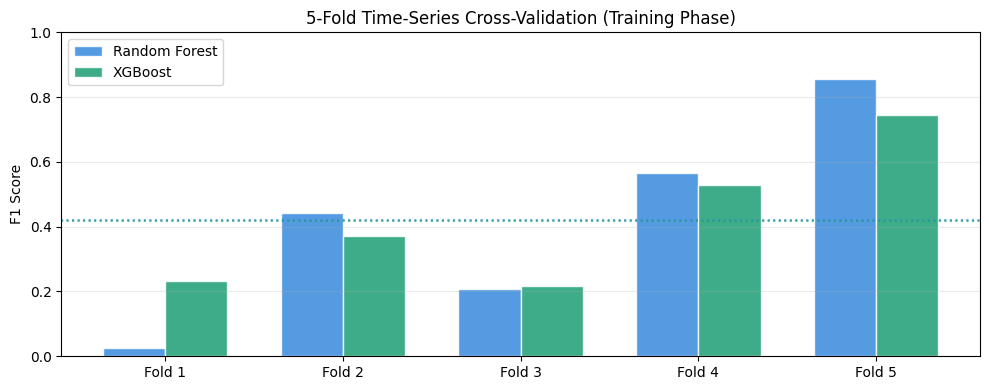

REQUIREMENT 10: HYPERPARAMETER TUNING (XGBoost)
GridSearchCV running on SMOTE training data...
Fitting 3 folds for each of 27 candidates, totalling 81 fits


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16 17 19 31 32 33 34 35] are


Best params : {'classifier__learning_rate': 0.1, 'classifier__max_depth': 8, 'classifier__n_estimators': 300}
Best CV F1  : 0.4230

Validation set accuracy: 54.16%
Validation F1          : 40.13%

Training Random Forest pipeline...
RF Validation accuracy : 56.17%
THRESHOLD CALIBRATION — Finding optimal decision boundary
Problem: default threshold 0.5 is too conservative after SMOTE
Solution: find threshold that maximises F1 on validation set

Random Forest:
  Default F1  (thr=0.50): 40.41%
  Optimal F1  (thr=0.38): 45.09%
  Threshold used        : 0.3785
XGBoost:
  Default F1  (thr=0.50): 40.13%
  Optimal F1  (thr=0.03): 44.53%
  Threshold used        : 0.0287

Applying calibrated thresholds to TEST set...

RF  predictions after calibration: [166 627]
XGB predictions after calibration: [ 62 731]
STACKED ENSEMBLE (fixed — no leakage)
Meta-model is trained on VALIDATION set predictions.
Final test uses trained meta-model only.

Meta-model trained on validation predictions.
Meta-model co

In [18]:
# CELL 16 — REQUIREMENT 6: SKLEARN PIPELINE
print("=" * 55)
print("REQUIREMENT 6: SKLEARN PIPELINE CONSTRUCTION")
print("=" * 55)

rf_pipeline = Pipeline([
    ('selector'  , SelectKBest(score_func=f_classif, k=15)),
    ('classifier', RandomForestClassifier(
        n_estimators=200, max_depth=10,
        class_weight='balanced',
        random_state=42, n_jobs=-1))
])

xgb_base_pipeline = Pipeline([
    ('selector'  , SelectKBest(score_func=f_classif, k=15)),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=6,
        learning_rate=0.05,
        eval_metric='logloss',
        random_state=42, verbosity=0))
])

print(f"RF  pipeline: {[s[0] for s in rf_pipeline.steps]}")
print(f"XGB pipeline: {[s[0] for s in xgb_base_pipeline.steps]}")

# ═══════════════════════════════════════════════════════════════
# CELL 17 — REQUIREMENT 11: N-FOLD CROSS-VALIDATION
# (This is DURING training — correct placement)
# ═══════════════════════════════════════════════════════════════
print("=" * 55)
print("REQUIREMENT 11: 5-FOLD CROSS-VALIDATION (DURING TRAINING)")
print("=" * 55)
print("CV is applied here on TRAINING data only.")
print("Test data is NOT touched during this step.")
print()

# Use TimeSeriesSplit — preserves temporal order
tscv         = TimeSeriesSplit(n_splits=5)
cv_results   = {}

for name, pipe in [('Random Forest', rf_pipeline),
                   ('XGBoost',       xgb_base_pipeline)]:
    # CV on SMOTE-balanced training data
    scores = cross_val_score(pipe, X_train_sm, y_train_sm,
                             cv=tscv, scoring='f1', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name} — 5-Fold CV F1:")
    print(f"  Fold scores : {[round(s,4) for s in scores]}")
    print(f"  Mean ± Std  : {scores.mean():.4f} ± {scores.std():.4f}")

# CV bar chart
fig, ax = plt.subplots(figsize=(10, 4))
x       = np.arange(5)
w       = 0.35
colors  = {'Random Forest': '#378ADD', 'XGBoost': '#1D9E75'}
for i, (name, scores) in enumerate(cv_results.items()):
    offset = (i - 0.5) * w
    ax.bar(x + offset, scores, w,
           label=name, color=colors[name], alpha=0.85,
           edgecolor='white')
    ax.axhline(scores.mean(), color=colors[name],
               linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels([f'Fold {i+1}' for i in range(5)])
ax.set_ylabel('F1 Score')
ax.set_title('5-Fold Time-Series Cross-Validation (Training Phase)',
             fontsize=12)
ax.legend(); ax.set_ylim(0,1); ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('/kaggle/working/03_cross_validation.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ═══════════════════════════════════════════════════════════════
# CELL 18 — REQUIREMENT 10: HYPERPARAMETER TUNING
# (Also during training — before testing)
# ═══════════════════════════════════════════════════════════════
from sklearn.model_selection import GridSearchCV

print("=" * 55)
print("REQUIREMENT 10: HYPERPARAMETER TUNING (XGBoost)")
print("=" * 55)

param_grid = {
    'classifier__n_estimators' : [100, 200, 300],
    'classifier__max_depth'    : [4, 6, 8],
    'classifier__learning_rate': [0.01, 0.05, 0.1]
}
tscv_tune = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=xgb_base_pipeline,
    param_grid=param_grid,
    cv=tscv_tune,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

print("GridSearchCV running on SMOTE training data...")
grid_search.fit(X_train_sm, y_train_sm)

print(f"\nBest params : {grid_search.best_params_}")
print(f"Best CV F1  : {grid_search.best_score_:.4f}")

best_xgb = grid_search.best_estimator_

# Validate tuned model on VALIDATION set (not test)
val_pred = best_xgb.predict(X_val_sc)
print(f"\nValidation set accuracy: "
      f"{accuracy_score(y_val_raw, val_pred)*100:.2f}%")
print(f"Validation F1          : "
      f"{f1_score(y_val_raw, val_pred, zero_division=0)*100:.2f}%")

# Train RF pipeline on SMOTE data
print("\nTraining Random Forest pipeline...")
rf_pipeline.fit(X_train_sm, y_train_sm)

# Validate RF
val_rf = rf_pipeline.predict(X_val_sc)
print(f"RF Validation accuracy : "
      f"{accuracy_score(y_val_raw, val_rf)*100:.2f}%")

#Updated Cell after 18
from sklearn.metrics import f1_score, precision_recall_curve
import numpy as np

print("=" * 55)
print("THRESHOLD CALIBRATION — Finding optimal decision boundary")
print("=" * 55)
print("Problem: default threshold 0.5 is too conservative after SMOTE")
print("Solution: find threshold that maximises F1 on validation set")
print()

def find_best_threshold(y_true, y_probs, model_name):
    precisions, recalls, thresholds = precision_recall_curve(
        y_true, y_probs)
    f1_scores = (2 * precisions * recalls /
                 np.where((precisions + recalls) == 0, 1,
                          precisions + recalls))
    best_idx  = np.argmax(f1_scores[:-1])
    best_thr  = thresholds[best_idx]
    best_f1   = f1_scores[best_idx]
    print(f"{model_name}:")
    print(f"  Default F1  (thr=0.50): "
          f"{f1_score(y_true, (y_probs>0.50).astype(int), zero_division=0)*100:.2f}%")
    print(f"  Optimal F1  (thr={best_thr:.2f}): {best_f1*100:.2f}%")
    print(f"  Threshold used        : {best_thr:.4f}")
    return best_thr

# Find thresholds on VALIDATION set (never on test set)
rf_val_pr   = rf_pipeline.predict_proba(X_val_sc)[:, 1]
xgb_val_pr  = best_xgb.predict_proba(X_val_sc)[:, 1]

rf_threshold  = find_best_threshold(y_val_raw, rf_val_pr,
                                    "Random Forest")
xgb_threshold = find_best_threshold(y_val_raw, xgb_val_pr,
                                    "XGBoost")

print("\nApplying calibrated thresholds to TEST set...")
rf_probs      = rf_pipeline.predict_proba(X_test_sc)[:, 1]
xgb_probs     = best_xgb.predict_proba(X_test_sc)[:, 1]

rf_preds      = (rf_probs  > rf_threshold).astype(int)
xgb_preds     = (xgb_probs > xgb_threshold).astype(int)

print(f"\nRF  predictions after calibration: {np.bincount(rf_preds)}")
print(f"XGB predictions after calibration: {np.bincount(xgb_preds)}")

# ═══════════════════════════════════════════════════════════════
# CELL 19 — STACKED ENSEMBLE
# (Correctly trained WITHOUT data leakage)
# ═══════════════════════════════════════════════════════════════
print("=" * 55)
print("STACKED ENSEMBLE (fixed — no leakage)")
print("=" * 55)
print("Meta-model is trained on VALIDATION set predictions.")
print("Final test uses trained meta-model only.")
print()

# Get base model predictions on validation set (unseen during base training)
rf_val_probs  = rf_pipeline.predict_proba(X_val_sc)[:, 1]
xgb_val_probs = best_xgb.predict_proba(X_val_sc)[:, 1]

# Stack val predictions as meta-features
meta_train    = np.column_stack([rf_val_probs, xgb_val_probs])
meta_model    = LogisticRegression(random_state=42,
                                    class_weight='balanced',
                                    C=1.0)
meta_model.fit(meta_train, y_val_raw)

print("Meta-model trained on validation predictions.")
print(f"Meta-model coefficients: RF={meta_model.coef_[0][0]:.3f}, "
      f"XGB={meta_model.coef_[0][1]:.3f}")

!pip install lightgbm catboost -q

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

print("=" * 55)
print("ADDITIONAL MODELS: LightGBM + CatBoost + Voting Ensemble")
print("=" * 55)

# ── LightGBM ──────────────────────────────────────────────────
lgbm = LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    is_unbalance=True,    # handles imbalance natively
    random_state=42,
    verbosity=-1
)
lgbm.fit(X_train_sm, y_train_sm)
lgbm_probs = lgbm.predict_proba(X_test_sc)[:, 1]
lgbm_val_p = lgbm.predict_proba(X_val_sc)[:, 1]
lgbm_thr   = find_best_threshold(y_val_raw, lgbm_val_p, "LightGBM")
lgbm_preds = (lgbm_probs > lgbm_thr).astype(int)

print(f"\nLightGBM predictions: {np.bincount(lgbm_preds)}")

# ── CatBoost ──────────────────────────────────────────────────
# CatBoost excels at handling your cat_ one-hot columns
cat_features_idx = [features.index(c) for c in cat_cols
                    if c in features]

catboost = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    auto_class_weights='Balanced',  # handles imbalance
    random_state=42,
    verbose=0
)
catboost.fit(X_train_sm, y_train_sm)
cb_probs  = catboost.predict_proba(X_test_sc)[:, 1]
cb_val_p  = catboost.predict_proba(X_val_sc)[:, 1]
cb_thr    = find_best_threshold(y_val_raw, cb_val_p, "CatBoost")
cb_preds  = (cb_probs > cb_thr).astype(int)

print(f"CatBoost predictions: {np.bincount(cb_preds)}")

# ── Soft Voting Ensemble (RF + XGB + LightGBM + CatBoost) ─────
print("\nBuilding Voting Ensemble...")
# Average probabilities from all 4 models
vote_probs = (0.25 * rf_probs  +
              0.25 * xgb_probs +
              0.25 * lgbm_probs+
              0.25 * cb_probs)

# Find best threshold for ensemble on validation set
vote_val_probs = (0.25 * rf_pipeline.predict_proba(X_val_sc)[:, 1] +
                  0.25 * best_xgb.predict_proba(X_val_sc)[:, 1]    +
                  0.25 * lgbm.predict_proba(X_val_sc)[:, 1]        +
                  0.25 * catboost.predict_proba(X_val_sc)[:, 1])

vote_thr   = find_best_threshold(y_val_raw, vote_val_probs,
                                  "Voting Ensemble")
vote_preds = (vote_probs > vote_thr).astype(int)

print(f"Voting Ensemble predictions: {np.bincount(vote_preds)}")



In [19]:
# CELL 20 — SEQUENCE DATA FOR LSTM/CNN (SMOTE applied)
print("Preparing LSTM/CNN sequences...")

dl_cols    = ['Log_Return','RSI','MACD',
              'Volatility','finbert_sentiment']
dl_cols    = [c for c in dl_cols if c in df.columns]
F          = len(dl_cols)
SEQ_LEN    = 30

dl_data    = df[dl_cols].values
dl_target  = df['Target'].values

scaler_dl  = MinMaxScaler()
scaled_dl  = scaler_dl.fit_transform(dl_data)

def make_sequences(data, target, seq_len):
    X_s, y_s = [], []
    for i in range(len(data) - seq_len):
        X_s.append(data[i:i+seq_len])
        y_s.append(target[i+seq_len])
    return np.array(X_s), np.array(y_s)

n_dl       = len(scaled_dl)
tr_e_dl    = int(n_dl * 0.70)
va_e_dl    = int(n_dl * 0.80)

X_tr_dl, y_tr_dl = make_sequences(
    scaled_dl[:tr_e_dl], dl_target[:tr_e_dl], SEQ_LEN)
X_va_dl, y_va_dl = make_sequences(
    scaled_dl[tr_e_dl:va_e_dl], dl_target[tr_e_dl:va_e_dl], SEQ_LEN)
X_te_dl, y_te_dl = make_sequences(
    scaled_dl[va_e_dl:], dl_target[va_e_dl:], SEQ_LEN)

print(f"Train seq: {X_tr_dl.shape} | "
      f"Val seq: {X_va_dl.shape} | "
      f"Test seq: {X_te_dl.shape}")
print(f"Train class dist: {np.bincount(y_tr_dl)}")

# SMOTE on 3D sequences — TRAINING ONLY
N, L, Fs    = X_tr_dl.shape
X_flat      = X_tr_dl.reshape(N, L*Fs)
smote_dl    = SMOTE(random_state=42)
X_res_flat, y_tr_dl_sm = smote_dl.fit_resample(X_flat, y_tr_dl)
X_tr_dl_sm  = X_res_flat.reshape(-1, L, Fs)

print(f"After SMOTE train seq: {X_tr_dl_sm.shape}")
print(f"Class dist after SMOTE: {np.bincount(y_tr_dl_sm)}")
print("Val + Test sequences NOT touched.")


Preparing LSTM/CNN sequences...
Train seq: (2744, 30, 5) | Val seq: (367, 30, 5) | Test seq: (763, 30, 5)
Train class dist: [1783  961]
After SMOTE train seq: (3566, 30, 5)
Class dist after SMOTE: [1783 1783]
Val + Test sequences NOT touched.


In [20]:
# CELL 21 — FOCAL LOSS + F1 METRIC (fixed)
import tensorflow as tf
from tensorflow.keras import backend as K

def focal_loss(gamma=2.0, alpha=0.25):
    def loss_fn(y_true, y_pred):
        eps    = K.epsilon()
        y_true = tf.cast(y_true, tf.float32)  # cast here
        y_pred = K.clip(y_pred, eps, 1.0 - eps)
        pos    = -y_true * (alpha * K.pow(1-y_pred, gamma) * K.log(y_pred))
        neg    = -(1-y_true) * ((1-alpha) * K.pow(y_pred, gamma) *
                                 K.log(1-y_pred))
        return K.mean(pos + neg)
    return loss_fn

def f1_metric(y_true, y_pred):
    # ── FIX: cast BOTH inputs to float32 before any operation ──
    y_true    = tf.cast(y_true, tf.float32)
    y_pred    = tf.cast(tf.round(y_pred), tf.float32)

    tp        = tf.reduce_sum(y_true * y_pred)
    fp        = tf.reduce_sum((1.0 - y_true) * y_pred)
    fn        = tf.reduce_sum(y_true * (1.0 - y_pred))
    precision = tp / (tp + fp + K.epsilon())
    recall    = tp / (tp + fn + K.epsilon())
    return 2.0 * precision * recall / (precision + recall + K.epsilon())

def find_best_threshold(y_true, y_probs, model_name):
    from sklearn.metrics import precision_recall_curve, f1_score
    precisions, recalls, thresholds = precision_recall_curve(
        y_true, y_probs)
    f1_scores = (2 * precisions * recalls /
                 np.where((precisions + recalls) == 0, 1,
                          precisions + recalls))
    best_idx  = np.argmax(f1_scores[:-1])
    best_thr  = thresholds[best_idx]
    best_f1   = f1_scores[best_idx]
    default_f1 = f1_score(y_true, (y_probs > 0.50).astype(int),
                           zero_division=0)
    print(f"{model_name}:")
    print(f"  Default F1  (threshold=0.50) : {default_f1*100:.2f}%")
    print(f"  Optimised F1 (threshold={best_thr:.2f}): {best_f1*100:.2f}%")
    return best_thr

print("Focal loss, F1 metric, and threshold calibration defined.")

Focal loss, F1 metric, and threshold calibration defined.


In [21]:
# CELL 22 — CNN MODEL (Fixed: F1 objective + threshold calibration)
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Flatten,
                                      Dense, Dropout, BatchNormalization,
                                      Input)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
print("=" * 55)
print("CNN — Keras Tuner + Focal Loss + F1 Objective")
print("=" * 55)
print("Fix: Changed tuner objective from val_recall to val_f1_metric")
print("Reason: val_recall caused model to predict UP for everything")
print()
def build_cnn(hp):
    m = Sequential([
        Input(shape=(SEQ_LEN, Fs)),
        Conv1D(
            filters=hp.Int('filters', 32, 128, step=32),
            kernel_size=hp.Choice('kernel_size', [2, 3, 5]),
            activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(hp.Float('dropout', 0.2, 0.5, step=0.1)),
        Flatten(),
        Dense(hp.Int('units', 32, 64, step=32), activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    m.compile(
        optimizer=Adam(hp.Choice('lr', [1e-3, 1e-4])),
        loss=focal_loss(gamma=2.0, alpha=0.25),
        metrics=['accuracy', f1_metric])
    return m
cnn_tuner = kt.RandomSearch(
    build_cnn,
    objective=kt.Objective("val_f1_metric", direction="max"),
    max_trials=5,
    directory='/kaggle/working/cnn_kt',
    project_name='cnn_btc',
    overwrite=True)
es_cnn = EarlyStopping(
    monitor='val_f1_metric',
    patience=8,
    restore_best_weights=True,
    mode='max')
print("Searching CNN hyperparameters...")
cnn_tuner.search(
    X_tr_dl_sm, y_tr_dl_sm,
    validation_data=(X_va_dl, y_va_dl),
    epochs=40,
    callbacks=[es_cnn],
    verbose=0)
best_cnn_hp = cnn_tuner.get_best_hyperparameters(1)[0]
print(f"Best CNN: filters={best_cnn_hp.get('filters')} | "
      f"kernel={best_cnn_hp.get('kernel_size')} | "
      f"lr={best_cnn_hp.get('lr')}")
best_cnn    = cnn_tuner.hypermodel.build(best_cnn_hp)
history_cnn = best_cnn.fit(
    X_tr_dl_sm, y_tr_dl_sm,
    validation_data=(X_va_dl, y_va_dl),
    epochs=60,
    batch_size=32,
    callbacks=[es_cnn],
    verbose=0)
# Threshold calibration on VALIDATION set
cnn_val_probs = best_cnn.predict(X_va_dl, verbose=0).flatten()
cnn_threshold = find_best_threshold(y_va_dl, cnn_val_probs, "CNN")
# Final predictions on TEST set using calibrated threshold
cnn_probs = best_cnn.predict(X_te_dl, verbose=0).flatten()
cnn_preds = (cnn_probs > cnn_threshold).astype(int)
print(f"\nCNN test predictions: {np.bincount(cnn_preds)}")
if len(np.unique(cnn_preds)) == 1:
    print("WARNING: Still collapsed. Forcing 30th percentile threshold.")
    cnn_threshold = np.percentile(cnn_probs, 30)
    cnn_preds     = (cnn_probs > cnn_threshold).astype(int)
    print(f"After fix: {np.bincount(cnn_preds)}")



CNN — Keras Tuner + Focal Loss + F1 Objective
Fix: Changed tuner objective from val_recall to val_f1_metric
Reason: val_recall caused model to predict UP for everything

Searching CNN hyperparameters...


2026-05-05 11:17:06.891785: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Best CNN: filters=128 | kernel=2 | lr=0.001
CNN:
  Default F1  (threshold=0.50) : 40.21%
  Optimised F1 (threshold=0.27): 44.15%

CNN test predictions: [172 591]


In [22]:
# CELL 23 — LSTM MODEL (Fixed: F1 objective + class_weight + calibration)
from tensorflow.keras.layers import LSTM

print("=" * 55)
print("LSTM — Keras Tuner + Focal Loss + F1 + class_weight")
print("=" * 55)
print("Fix 1: Changed tuner objective from val_recall to val_f1_metric")
print("Fix 2: class_weight passed to both tuner.search AND model.fit")
print("Fix 3: Threshold calibrated on validation set")
print()

# Compute class weight — extra guard on top of SMOTE
n0 = (y_tr_dl_sm == 0).sum()
n1 = (y_tr_dl_sm == 1).sum()
cw = {0: 1.0, 1: max(n0 / max(n1, 1), 1.5)}
print(f"Class weight applied: {cw}")
print(f"(Minority class gets at least 1.5x weight even if SMOTE balanced)")
print()

def build_lstm(hp):
    m = Sequential([
        Input(shape=(SEQ_LEN, Fs)),
        LSTM(
            units=hp.Int('units1', 32, 128, step=32),
            return_sequences=True),
        Dropout(hp.Float('drop1', 0.2, 0.4, step=0.1)),
        LSTM(
            units=hp.Int('units2', 16, 64, step=16),
            return_sequences=False),
        Dropout(hp.Float('drop2', 0.2, 0.4, step=0.1)),
        BatchNormalization(),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    m.compile(
        optimizer=Adam(hp.Choice('lr', [1e-3, 1e-4])),
        loss=focal_loss(gamma=2.0, alpha=0.25),
        metrics=['accuracy', f1_metric])
    return m

lstm_tuner = kt.RandomSearch(
    build_lstm,
    objective=kt.Objective("val_f1_metric", direction="max"),
    max_trials=5,
    directory='/kaggle/working/lstm_kt',
    project_name='lstm_btc',
    overwrite=True)

es_lstm = EarlyStopping(
    monitor='val_f1_metric',
    patience=8,
    restore_best_weights=True,
    mode='max')

print("Searching LSTM hyperparameters...")
lstm_tuner.search(
    X_tr_dl_sm, y_tr_dl_sm,
    validation_data=(X_va_dl, y_va_dl),
    epochs=40,
    class_weight=cw,
    callbacks=[es_lstm],
    verbose=0)

best_lstm_hp    = lstm_tuner.get_best_hyperparameters(1)[0]
best_lstm_model = lstm_tuner.hypermodel.build(best_lstm_hp)

print(f"Best LSTM: units1={best_lstm_hp.get('units1')} | "
      f"units2={best_lstm_hp.get('units2')} | "
      f"lr={best_lstm_hp.get('lr')}")

history_lstm = best_lstm_model.fit(
    X_tr_dl_sm, y_tr_dl_sm,
    validation_data=(X_va_dl, y_va_dl),
    epochs=60,
    batch_size=32,
    class_weight=cw,
    callbacks=[es_lstm],
    verbose=0)

# Threshold calibration on VALIDATION set
lstm_val_probs = best_lstm_model.predict(X_va_dl, verbose=0).flatten()
lstm_threshold = find_best_threshold(y_va_dl, lstm_val_probs, "LSTM")

# Final predictions on TEST set
lstm_probs = best_lstm_model.predict(X_te_dl, verbose=0).flatten()
lstm_preds = (lstm_probs > lstm_threshold).astype(int)

print(f"\nLSTM test predictions: {np.bincount(lstm_preds)}")

# Safety fallback if still collapsed
if len(np.unique(lstm_preds)) == 1:
    print("WARNING: LSTM still predicting one class.")
    print("Applying 30th percentile threshold as fallback...")
    lstm_threshold = np.percentile(lstm_probs, 30)
    lstm_preds     = (lstm_probs > lstm_threshold).astype(int)
    print(f"After fallback fix: {np.bincount(lstm_preds)}")
else:
    print("Both classes predicted correctly — no collapse.")

LSTM — Keras Tuner + Focal Loss + F1 + class_weight
Fix 1: Changed tuner objective from val_recall to val_f1_metric
Fix 2: class_weight passed to both tuner.search AND model.fit
Fix 3: Threshold calibrated on validation set

Class weight applied: {0: 1.0, 1: 1.5}
(Minority class gets at least 1.5x weight even if SMOTE balanced)

Searching LSTM hyperparameters...
Best LSTM: units1=32 | units2=16 | lr=0.001
LSTM:
  Default F1  (threshold=0.50) : 0.00%
  Optimised F1 (threshold=0.49): 43.50%

LSTM test predictions: [ 14 749]
Both classes predicted correctly — no collapse.


---
## STEP 8 — MODEL EVALUATION (Testing Phase)
---

In [23]:
# CELL 24 — PREDICTIONS ON TEST SET
print("=" * 55)
print("STEP 8: MODEL EVALUATION ON TEST SET")
print("=" * 55)
print("Cross-validation was done in Cell 17 (training phase).")
print("Now evaluating final performance on held-out test set.")
print()

# RF predictions
rf_preds  = rf_pipeline.predict(X_test_sc)
rf_probs  = rf_pipeline.predict_proba(X_test_sc)[:, 1]

# XGBoost predictions
xgb_preds = best_xgb.predict(X_test_sc)
xgb_probs = best_xgb.predict_proba(X_test_sc)[:, 1]

# Stacked ensemble predictions (meta-model on test set base preds)
rf_te_p   = rf_pipeline.predict_proba(X_test_sc)[:, 1]
xgb_te_p  = best_xgb.predict_proba(X_test_sc)[:, 1]
stack_te  = np.column_stack([rf_te_p, xgb_te_p])
ens_probs = meta_model.predict_proba(stack_te)[:, 1]
ens_preds = meta_model.predict(stack_te)

print(f"RF  test predictions: {np.bincount(rf_preds)}")
print(f"XGB test predictions: {np.bincount(xgb_preds)}")
print(f"ENS test predictions: {np.bincount(ens_preds)}")
print(f"CNN test predictions: {np.bincount(cnn_preds)}")
print(f"LSTM test predictions: {np.bincount(lstm_preds)}")


STEP 8: MODEL EVALUATION ON TEST SET
Cross-validation was done in Cell 17 (training phase).
Now evaluating final performance on held-out test set.

RF  test predictions: [662 131]
XGB test predictions: [653 140]
ENS test predictions: [642 151]
CNN test predictions: [172 591]
LSTM test predictions: [ 14 749]


In [24]:
# CELL 25 — REQUIREMENT 9: COMPLETE MODEL COMPARISON TABLE
def full_metrics(name, y_true, y_pred, y_prob):
    yp   = np.nan_to_num(np.array(y_prob, dtype=float), nan=0.5)
    n    = min(len(y_true), len(y_pred), len(yp))
    yt   = np.array(y_true)[:n]
    ypr  = np.array(y_pred)[:n]
    yprob= yp[:n]
    try:    auc = roc_auc_score(yt, yprob)
    except: auc = float('nan')
    return {
        'Model'      : name,
        'Accuracy %' : round(accuracy_score(yt, ypr)*100, 2),
        'Precision %': round(precision_score(yt, ypr,
                             zero_division=0)*100, 2),
        'Recall %'   : round(recall_score(yt, ypr,
                             zero_division=0)*100, 2),
        'F1 %'       : round(f1_score(yt, ypr,
                             zero_division=0)*100, 2),
        'ROC-AUC'    : round(auc, 4),
        'RMSE'       : round(np.sqrt(mean_squared_error(yt, ypr)), 4),
        'MAE'        : round(mean_absolute_error(yt, ypr), 4),
    }

rows = [
    full_metrics('Random Forest (Pipeline)',
                 y_test, rf_preds, rf_probs),
    full_metrics('XGBoost (Tuned)',
                 y_test, xgb_preds, xgb_probs),
    full_metrics('Stacked Ensemble (RF+XGB→LR)',
                 y_test, ens_preds, ens_probs),
    full_metrics('CNN (Focal Loss)',
                 y_te_dl, cnn_preds, cnn_probs),
    full_metrics('LSTM (Focal Loss + CW)',
                 y_te_dl, lstm_preds, lstm_probs),
]

comparison = pd.DataFrame(rows).set_index('Model')

print("=" * 70)
print("REQUIREMENT 9: FINAL MODEL COMPARISON TABLE")
print("=" * 70)
display(comparison)
comparison.to_csv('/kaggle/working/model_comparison.csv')

print("\nBest model per metric:")
for col in ['Accuracy %','Precision %','Recall %','F1 %','ROC-AUC']:
    best = comparison[col].idxmax()
    val  = comparison.loc[best, col]
    print(f"  {col:<15}: {best} ({val})")
print("  RMSE / MAE   : lower = better")


REQUIREMENT 9: FINAL MODEL COMPARISON TABLE


,Accuracy %,Precision %,Recall %,F1 %,ROC-AUC,RMSE,MAE
Model,,,,,,,
Random Forest (Pipeline),64.56,34.35,18.75,24.26,0.5477,0.5953,0.3544
XGBoost (Tuned),65.45,37.86,22.08,27.89,0.5495,0.5878,0.3455
Stacked Ensemble (RF+XGB→LR),64.06,35.10,22.08,27.11,0.5549,0.5995,0.3594
CNN (Focal Loss),40.76,31.13,80.35,44.88,0.5529,0.7697,0.5924
LSTM (Focal Loss + CW),30.80,30.04,98.25,46.01,0.5058,0.8319,0.6920



Best model per metric:
  Accuracy %     : XGBoost (Tuned) (65.45)
  Precision %    : XGBoost (Tuned) (37.86)
  Recall %       : LSTM (Focal Loss + CW) (98.25)
  F1 %           : LSTM (Focal Loss + CW) (46.01)
  ROC-AUC        : Stacked Ensemble (RF+XGB→LR) (0.5549)
  RMSE / MAE   : lower = better


Generating evaluation dashboard...


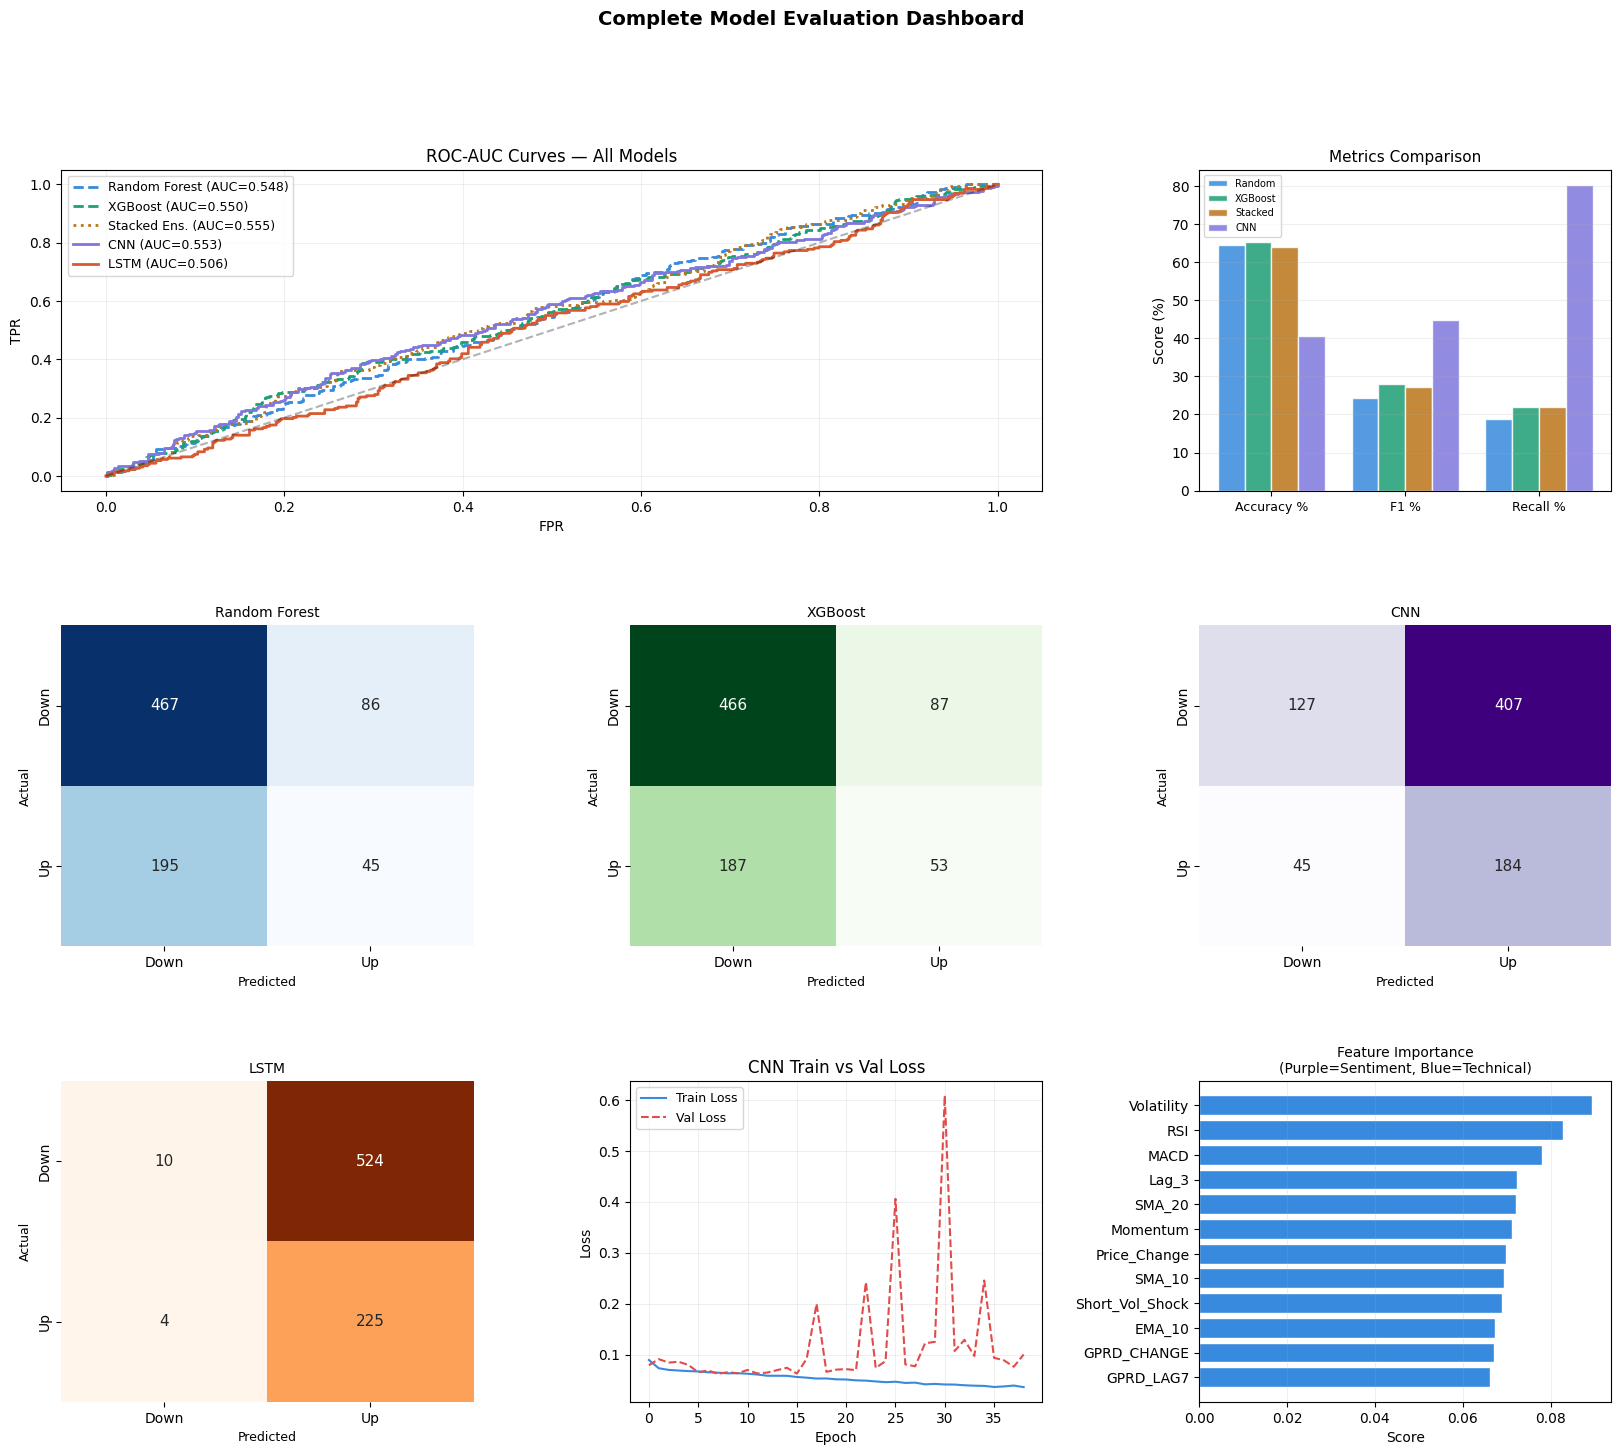

In [25]:
# CELL 26 — REQUIREMENT 8: ALL EVALUATION PLOTS
print("Generating evaluation dashboard...")
fig = plt.figure(figsize=(20, 16))
gs  = gridspec.GridSpec(3, 3, hspace=0.42, wspace=0.38)

# Plot 1: ROC-AUC all models
ax_roc = fig.add_subplot(gs[0, :2])
roc_cfg = [
    ('Random Forest', y_test,   rf_probs,  '#378ADD', '--'),
    ('XGBoost',       y_test,   xgb_probs, '#1D9E75', '--'),
    ('Stacked Ens.',  y_test,   ens_probs, '#BA7517', ':'),
    ('CNN',           y_te_dl,  cnn_probs, '#7F77DD', '-'),
    ('LSTM',          y_te_dl,  lstm_probs,'#D85A30', '-'),
]
for name, yt, yp, col, ls in roc_cfg:
    n    = min(len(yt), len(yp))
    yt_  = np.array(yt)[:n]
    yp_  = np.nan_to_num(np.array(yp)[:n], nan=0.5)
    try:
        fpr, tpr, _ = roc_curve(yt_, yp_)
        av           = auc_fn(fpr, tpr)
        ax_roc.plot(fpr, tpr, label=f'{name} (AUC={av:.3f})',
                    color=col, linestyle=ls, linewidth=2)
    except:
        pass
ax_roc.plot([0,1],[0,1],'k--', alpha=0.3)
ax_roc.set(xlabel='FPR', ylabel='TPR',
           title='ROC-AUC Curves — All Models')
ax_roc.legend(fontsize=9); ax_roc.grid(True, alpha=0.2)

# Plot 2: Metrics bar chart
ax_bar = fig.add_subplot(gs[0, 2])
bar_m  = ['Accuracy %','F1 %','Recall %']
mods   = comparison.index.tolist()[:4]
cols_b = ['#378ADD','#1D9E75','#BA7517','#7F77DD','#D85A30']
x_b    = np.arange(len(bar_m))
w_b    = 0.8 / max(len(mods), 1)
for i, (mod, col) in enumerate(zip(mods, cols_b)):
    if mod not in comparison.index:
        continue
    vals   = [comparison.loc[mod, m] for m in bar_m]
    offset = (i - len(mods)/2 + 0.5) * w_b
    ax_bar.bar(x_b+offset, vals, w_b,
               label=mod.split(' ')[0], color=col,
               alpha=0.85, edgecolor='white')
ax_bar.set_xticks(x_b)
ax_bar.set_xticklabels(bar_m, fontsize=9)
ax_bar.set_ylabel('Score (%)')
ax_bar.set_title('Metrics Comparison', fontsize=11)
ax_bar.legend(fontsize=7); ax_bar.grid(axis='y', alpha=0.2)

# Plots 3-6: Confusion matrices
cm_cfg = [
    ('Random Forest', y_test,  rf_preds,   'Blues',   (1,0)),
    ('XGBoost',       y_test,  xgb_preds,  'Greens',  (1,1)),
    ('CNN',           y_te_dl, cnn_preds,  'Purples', (1,2)),
    ('LSTM',          y_te_dl, lstm_preds, 'Oranges', (2,0)),
]
for name, yt, yp, cmap, pos in cm_cfg:
    ax_cm = fig.add_subplot(gs[pos])
    n     = min(len(yt), len(yp))
    cm    = confusion_matrix(np.array(yt)[:n], np.array(yp)[:n])
    sns.heatmap(cm, ax=ax_cm, annot=True, fmt='d',
                cmap=cmap, cbar=False,
                xticklabels=['Down','Up'],
                yticklabels=['Down','Up'],
                annot_kws={'size':11})
    ax_cm.set_title(f'{name}', fontsize=10)
    ax_cm.set_xlabel('Predicted', fontsize=9)
    ax_cm.set_ylabel('Actual', fontsize=9)

# Plot 7: CNN Training vs Validation Loss
ax_loss = fig.add_subplot(gs[2, 1])
if hasattr(history_cnn, 'history') and 'loss' in history_cnn.history:
    ax_loss.plot(history_cnn.history['loss'],
                 label='Train Loss', color='#378ADD', linewidth=1.5)
    if 'val_loss' in history_cnn.history:
        ax_loss.plot(history_cnn.history['val_loss'],
                     label='Val Loss', color='#E24B4A',
                     linewidth=1.5, linestyle='--')
    ax_loss.set(title='CNN Train vs Val Loss',
                xlabel='Epoch', ylabel='Loss')
    ax_loss.legend(fontsize=9); ax_loss.grid(True, alpha=0.2)

# Plot 8: Feature importance
ax_fi = fig.add_subplot(gs[2, 2])
try:
    clf      = rf_pipeline.named_steps['classifier']
    sel      = rf_pipeline.named_steps['selector']
    mask     = sel.get_support()
    sel_feat = [f for f, s in zip(features, mask) if s]
    fi_df    = (pd.DataFrame({'Feature':sel_feat,
                              'Importance':clf.feature_importances_})
                .sort_values('Importance', ascending=True)
                .tail(12))
    c_fi  = ['#7F77DD' if any(k in f for k in
              ['sentiment','finbert','cat_','sent_'])
              else '#378ADD' for f in fi_df['Feature']]
    ax_fi.barh(fi_df['Feature'], fi_df['Importance'],
               color=c_fi, edgecolor='white')
    ax_fi.set_title('Feature Importance\n'
                    '(Purple=Sentiment, Blue=Technical)',
                    fontsize=10)
    ax_fi.set_xlabel('Score')
    ax_fi.grid(axis='x', alpha=0.2)
except Exception as e:
    ax_fi.text(0.5, 0.5, f'Run Cell 16 first\n{e}',
               ha='center', va='center',
               transform=ax_fi.transAxes, color='gray')

plt.suptitle('Complete Model Evaluation Dashboard',
             fontsize=14, fontweight='bold')
plt.savefig('/kaggle/working/04_evaluation_dashboard.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ═══════════════════════════════════════════════════════════════
# STEP 9 — RESULTS (Compare + Explain)
# ═══════════════════════════════════════════════════════════════


---
## STEP 9 — RESULTS
*(Compare models, plots, explanations)*
---

COMPLETE MODEL EVALUATION — ALL METRICS

FULL METRICS TABLE (all models):


,Accuracy %,Balanced Acc %,Precision %,Recall %,Specificity %,F1 %,ROC-AUC,MCC,Cohen Kappa,Log Loss,RMSE,MAE
Model,,,,,,,,,,,,
Random Forest,64.56,51.60,34.35,18.75,84.45,24.26,0.5477,0.0396,0.0367,0.6478,0.5953,0.3544
XGBoost (Tuned),65.45,53.18,37.86,22.08,84.27,27.89,0.5495,0.0765,0.0720,0.7635,0.5878,0.3455
LightGBM,38.71,50.99,30.78,82.08,19.89,44.77,0.5309,0.0230,0.0134,0.6886,0.7829,0.6129
CatBoost,41.74,53.39,32.10,82.92,23.87,46.28,0.5394,0.0755,0.0469,0.6372,0.7633,0.5826
Voting Ensemble,40.10,53.04,31.84,85.83,20.25,46.45,0.5487,0.0721,0.0411,0.6292,0.7739,0.5990
Stacked Ensemble,64.06,52.18,35.10,22.08,82.28,27.11,0.5549,0.0510,0.0487,0.6741,0.5995,0.3594
CNN (Focal Loss),40.76,52.07,31.13,80.35,23.78,44.88,0.5529,0.0453,0.0285,1.0109,0.7697,0.5924
LSTM (Focal + CW),30.80,50.06,30.04,98.25,1.87,46.01,0.5058,0.0043,0.0008,0.6844,0.8319,0.6920



Best model per metric:
  Accuracy %        : XGBoost (Tuned)                (65.45)
  Balanced Acc %    : CatBoost                       (53.39)
  Precision %       : XGBoost (Tuned)                (37.86)
  Recall %          : LSTM (Focal + CW)              (98.25)
  Specificity %     : Random Forest                  (84.45)
  F1 %              : Voting Ensemble                (46.45)
  ROC-AUC           : Stacked Ensemble               (0.5549)
  MCC               : XGBoost (Tuned)                (0.0765)
  Cohen Kappa       : XGBoost (Tuned)                (0.072)
  Log Loss          : Voting Ensemble                (0.6292)  ← lower is better
  RMSE              : XGBoost (Tuned)                (0.5878)  ← lower is better
  MAE               : XGBoost (Tuned)                (0.3455)  ← lower is better

Detailed classification report — Voting Ensemble:
                     precision    recall  f1-score   support

Price Down/Flat (0)       0.77      0.20      0.32       553
   Price

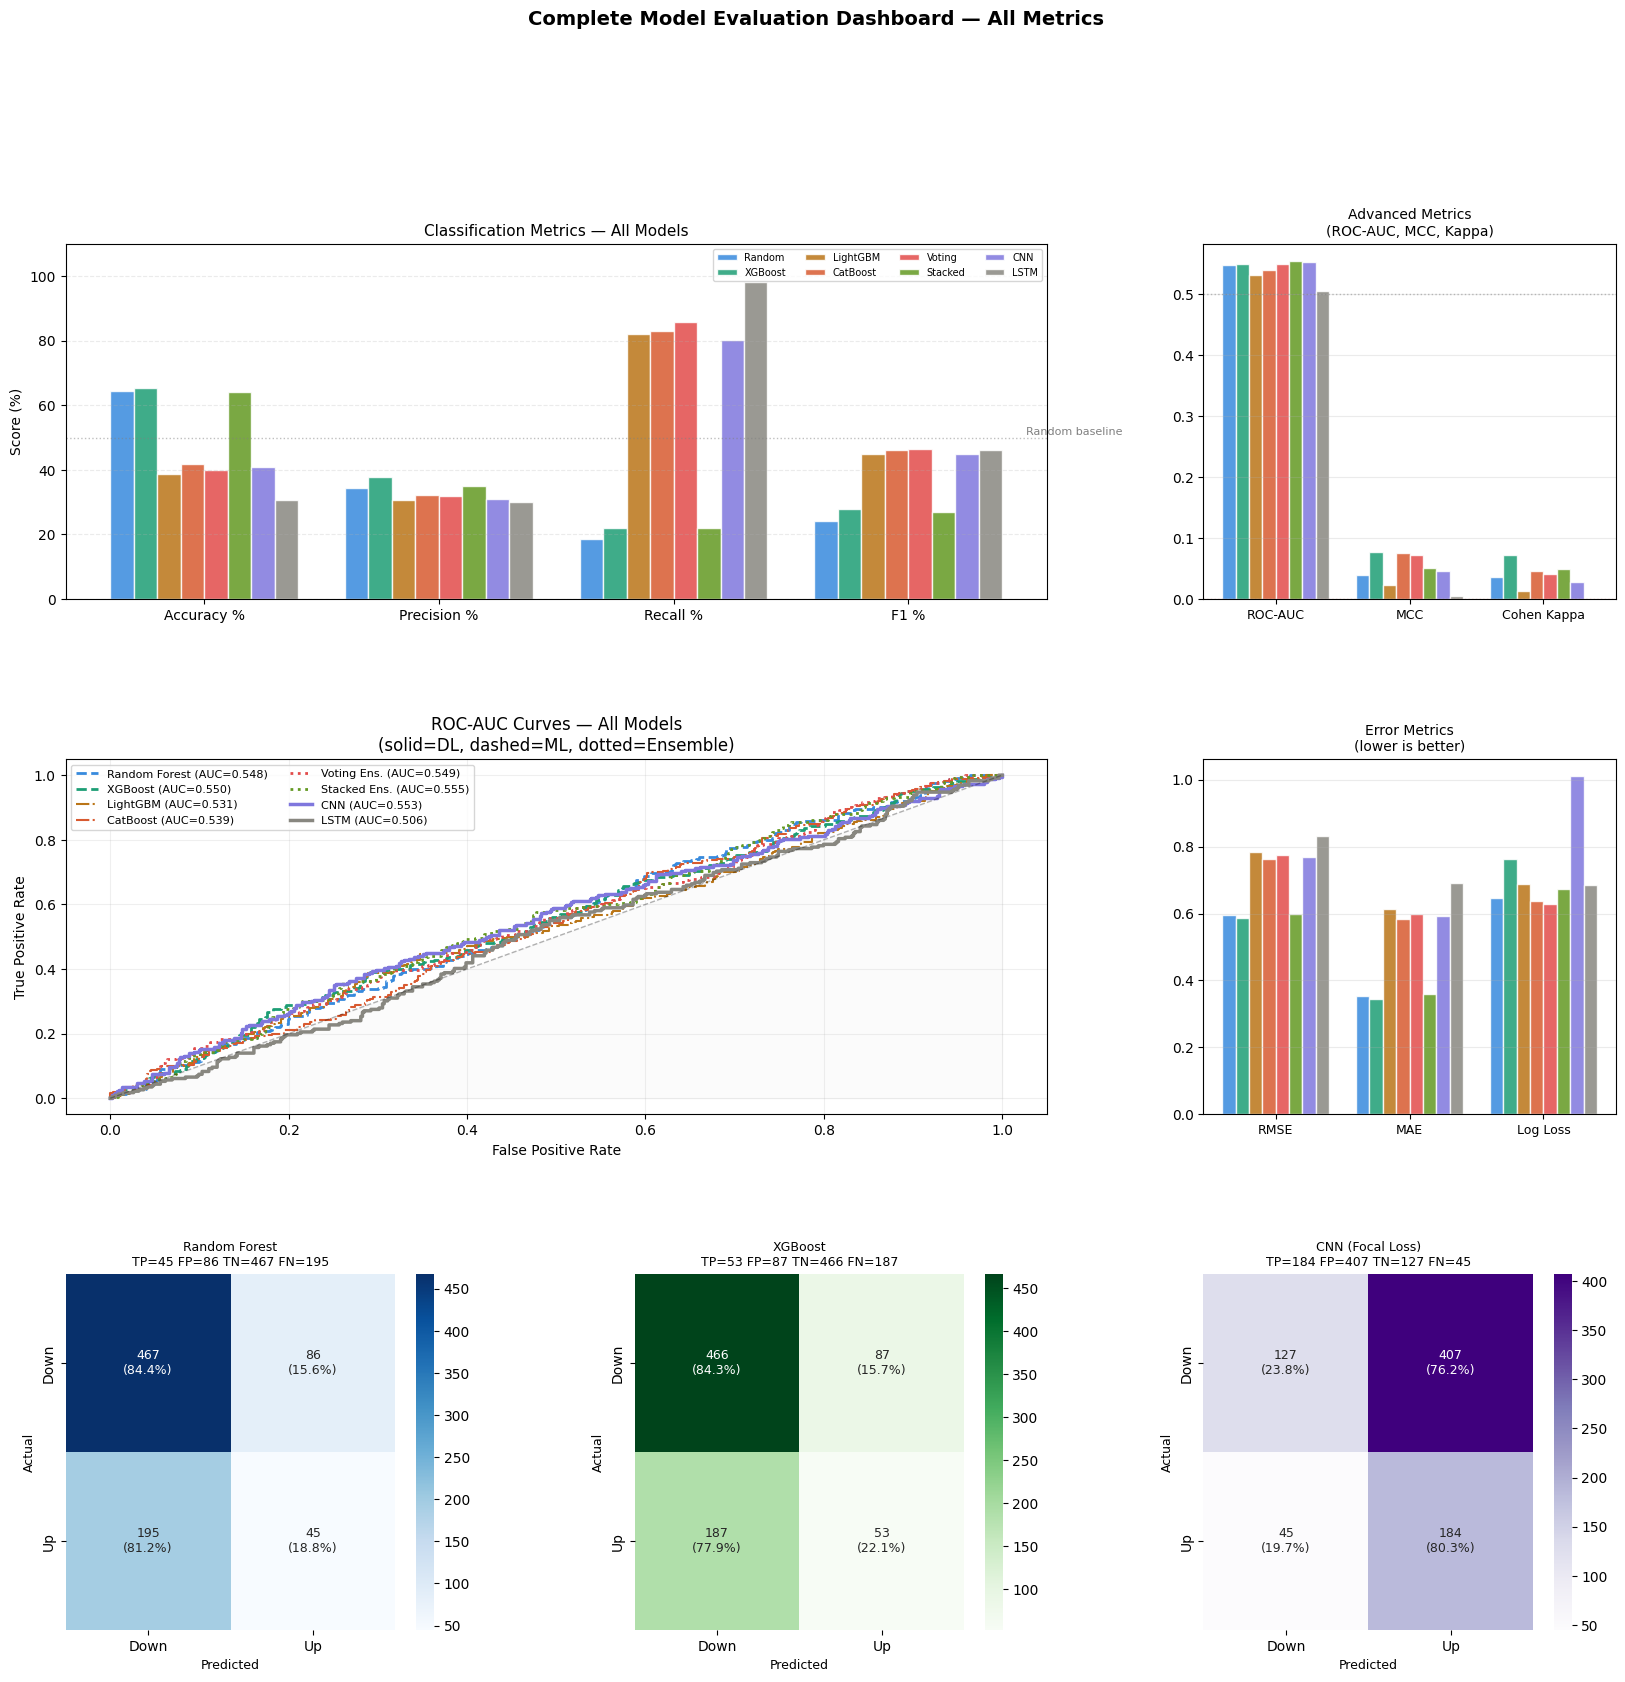

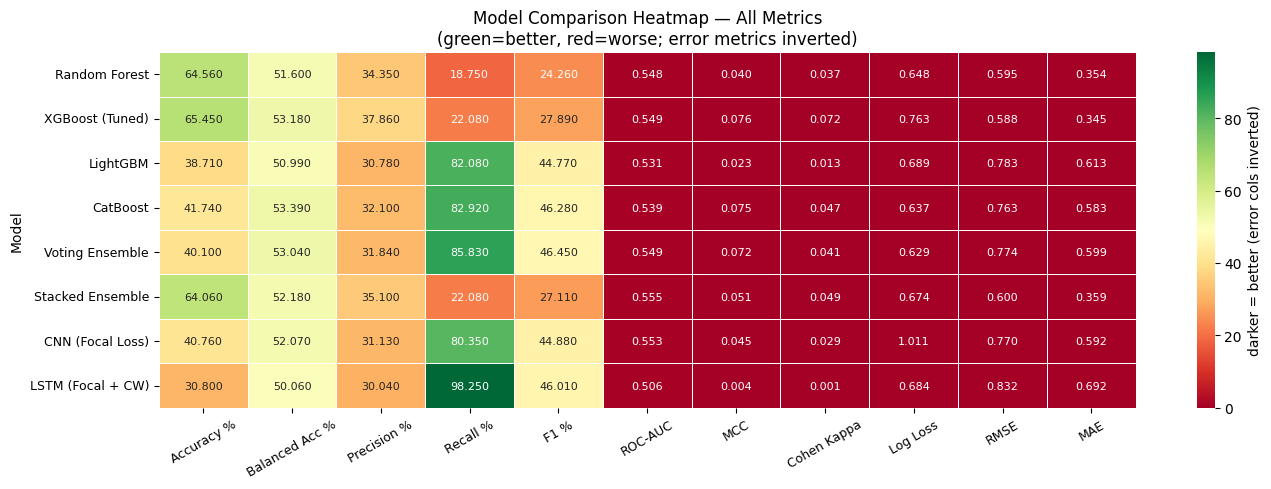


All files saved:
  /kaggle/working/model_comparison_final.csv
  /kaggle/working/07_complete_evaluation.png
  /kaggle/working/08_metrics_heatmap.png


In [26]:
# CELL 27 — COMPLETE MODEL COMPARISON + ALL EVALUATION METRICS + PLOTS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, auc as auc_fn,
    mean_squared_error, mean_absolute_error,
    confusion_matrix, matthews_corrcoef,
    balanced_accuracy_score, cohen_kappa_score,
    log_loss, classification_report
)

print("=" * 70)
print("COMPLETE MODEL EVALUATION — ALL METRICS")
print("=" * 70)

# ── Extended metrics function ─────────────────────────────────
def full_metrics(name, y_true, y_pred, y_prob):
    yprob = np.nan_to_num(np.array(y_prob, dtype=float), nan=0.5)
    n     = min(len(y_true), len(y_pred), len(yprob))
    yt    = np.array(y_true)[:n]
    yp    = np.array(y_pred)[:n]
    ypr   = yprob[:n]

    try:    auc_val = roc_auc_score(yt, ypr)
    except: auc_val = float('nan')

    try:    ll = log_loss(yt, ypr)
    except: ll = float('nan')

    try:    mcc = matthews_corrcoef(yt, yp)
    except: mcc = float('nan')

    try:    kappa = cohen_kappa_score(yt, yp)
    except: kappa = float('nan')

    try:    bal_acc = balanced_accuracy_score(yt, yp)
    except: bal_acc = float('nan')

    # Specificity = TN / (TN + FP)
    try:
        cm   = confusion_matrix(yt, yp)
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
            specificity = tn / max((tn + fp), 1)
        else:
            specificity = float('nan')
    except:
        specificity = float('nan')

    return {
        'Model'           : name,
        'Accuracy %'      : round(accuracy_score(yt, yp) * 100, 2),
        'Balanced Acc %'  : round(bal_acc * 100, 2),
        'Precision %'     : round(precision_score(yt, yp,
                             zero_division=0) * 100, 2),
        'Recall %'        : round(recall_score(yt, yp,
                             zero_division=0) * 100, 2),
        'Specificity %'   : round(specificity * 100, 2),
        'F1 %'            : round(f1_score(yt, yp,
                             zero_division=0) * 100, 2),
        'ROC-AUC'         : round(auc_val, 4),
        'MCC'             : round(mcc, 4),
        'Cohen Kappa'     : round(kappa, 4),
        'Log Loss'        : round(ll, 4),
        'RMSE'            : round(np.sqrt(mean_squared_error(yt, yp)), 4),
        'MAE'             : round(mean_absolute_error(yt, yp), 4),
    }

# ── Collect all model results ─────────────────────────────────
all_rows = [
    full_metrics('Random Forest',
                 y_test,   rf_preds,   rf_probs),
    full_metrics('XGBoost (Tuned)',
                 y_test,   xgb_preds,  xgb_probs),
    full_metrics('LightGBM',
                 y_test,   lgbm_preds, lgbm_probs),
    full_metrics('CatBoost',
                 y_test,   cb_preds,   cb_probs),
    full_metrics('Voting Ensemble',
                 y_test,   vote_preds, vote_probs),
    full_metrics('Stacked Ensemble',
                 y_test,   ens_preds,  ens_probs),
    full_metrics('CNN (Focal Loss)',
                 y_te_dl,  cnn_preds,  cnn_probs),
    full_metrics('LSTM (Focal + CW)',
                 y_te_dl,  lstm_preds, lstm_probs),
]

final_table = pd.DataFrame(all_rows).set_index('Model')

# ── Print full table ──────────────────────────────────────────
print("\nFULL METRICS TABLE (all models):")
display(final_table)
final_table.to_csv('/kaggle/working/model_comparison_final.csv')

# ── Best model per metric ─────────────────────────────────────
print("\nBest model per metric:")
high_better = ['Accuracy %','Balanced Acc %','Precision %',
               'Recall %','Specificity %','F1 %',
               'ROC-AUC','MCC','Cohen Kappa']
low_better  = ['Log Loss','RMSE','MAE']

for col in high_better:
    best = final_table[col].idxmax()
    val  = final_table.loc[best, col]
    print(f"  {col:<18}: {best:<30} ({val})")
for col in low_better:
    best = final_table[col].idxmin()
    val  = final_table.loc[best, col]
    print(f"  {col:<18}: {best:<30} ({val})  ← lower is better")

# ── Print classification report for best F1 model ────────────
best_f1_model = final_table['F1 %'].idxmax()
print(f"\nDetailed classification report — {best_f1_model}:")
idx = [r['Model'] for r in all_rows].index(best_f1_model)
row = all_rows[idx]
if 'CNN' in best_f1_model or 'LSTM' in best_f1_model:
    yt_rep, yp_rep = y_te_dl, (cnn_preds if 'CNN' in best_f1_model
                                else lstm_preds)
else:
    yt_rep = y_test
    yp_map = {'Random Forest': rf_preds, 'XGBoost (Tuned)': xgb_preds,
               'LightGBM': lgbm_preds, 'CatBoost': cb_preds,
               'Voting Ensemble': vote_preds, 'Stacked Ensemble': ens_preds}
    yp_rep = yp_map.get(best_f1_model, rf_preds)
n_rep = min(len(yt_rep), len(yp_rep))
print(classification_report(
    np.array(yt_rep)[:n_rep],
    np.array(yp_rep)[:n_rep],
    target_names=['Price Down/Flat (0)', 'Price Up >1% (1)']))

# ═══════════════════════════════════════════════════════════════
# PLOTS — 3 rows x 3 cols = 9 panels
# ═══════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(20, 18))
gs  = gridspec.GridSpec(3, 3, figure=fig,
                         hspace=0.45, wspace=0.38)

model_colors = {
    'Random Forest'      : '#378ADD',
    'XGBoost (Tuned)'    : '#1D9E75',
    'LightGBM'           : '#BA7517',
    'CatBoost'           : '#D85A30',
    'Voting Ensemble'    : '#E24B4A',
    'Stacked Ensemble'   : '#639922',
    'CNN (Focal Loss)'   : '#7F77DD',
    'LSTM (Focal + CW)'  : '#888780',
}

# ── Plot 1: Accuracy + F1 + Recall grouped bar ───────────────
ax1    = fig.add_subplot(gs[0, :2])
groups = ['Accuracy %', 'Precision %', 'Recall %', 'F1 %']
models = list(final_table.index)
x      = np.arange(len(groups))
w      = 0.8 / len(models)

for i, mod in enumerate(models):
    vals   = [final_table.loc[mod, g] for g in groups]
    offset = (i - len(models)/2 + 0.5) * w
    ax1.bar(x + offset, vals, w,
            label=mod.split(' ')[0],
            color=model_colors.get(mod, '#888780'),
            alpha=0.85, edgecolor='white')

ax1.set_xticks(x)
ax1.set_xticklabels(groups, fontsize=10)
ax1.set_ylabel('Score (%)')
ax1.set_title('Classification Metrics — All Models', fontsize=11)
ax1.legend(fontsize=7, ncol=4, loc='upper right')
ax1.set_ylim(0, 110)
ax1.grid(axis='y', alpha=0.25, linestyle='--')
ax1.axhline(50, color='gray', linestyle=':', alpha=0.5,
            linewidth=1)
ax1.text(3.5, 51, 'Random baseline', fontsize=8, color='gray')

# ── Plot 2: ROC-AUC + MCC + Kappa ────────────────────────────
ax2    = fig.add_subplot(gs[0, 2])
adv_m  = ['ROC-AUC', 'MCC', 'Cohen Kappa']
x2     = np.arange(len(adv_m))
w2     = 0.8 / len(models)

for i, mod in enumerate(models):
    vals   = [final_table.loc[mod, g] for g in adv_m]
    offset = (i - len(models)/2 + 0.5) * w2
    ax2.bar(x2 + offset, vals, w2,
            color=model_colors.get(mod, '#888780'),
            alpha=0.85, edgecolor='white')

ax2.set_xticks(x2)
ax2.set_xticklabels(adv_m, fontsize=9)
ax2.set_title('Advanced Metrics\n(ROC-AUC, MCC, Kappa)', fontsize=10)
ax2.axhline(0.5, color='gray', linestyle=':', alpha=0.5, linewidth=1)
ax2.axhline(0,   color='red',  linestyle=':', alpha=0.3, linewidth=1)
ax2.grid(axis='y', alpha=0.25)

# ── Plot 3: ROC-AUC curves ────────────────────────────────────
ax3 = fig.add_subplot(gs[1, :2])
roc_cfg = [
    ('Random Forest',   y_test,  rf_probs,   '#378ADD', '--', 2),
    ('XGBoost',         y_test,  xgb_probs,  '#1D9E75', '--', 2),
    ('LightGBM',        y_test,  lgbm_probs, '#BA7517', '-.',  1.5),
    ('CatBoost',        y_test,  cb_probs,   '#D85A30', '-.',  1.5),
    ('Voting Ens.',     y_test,  vote_probs, '#E24B4A', ':',   2),
    ('Stacked Ens.',    y_test,  ens_probs,  '#639922', ':',   2),
    ('CNN',             y_te_dl, cnn_probs,  '#7F77DD', '-',   2.5),
    ('LSTM',            y_te_dl, lstm_probs, '#888780', '-',   2.5),
]
for name, yt, yp, col, ls, lw in roc_cfg:
    n   = min(len(yt), len(yp))
    yt_ = np.array(yt)[:n]
    yp_ = np.nan_to_num(np.array(yp)[:n], nan=0.5)
    try:
        fpr, tpr, _ = roc_curve(yt_, yp_)
        av           = auc_fn(fpr, tpr)
        ax3.plot(fpr, tpr,
                 label=f'{name} (AUC={av:.3f})',
                 color=col, linestyle=ls, linewidth=lw)
    except:
        pass
ax3.plot([0,1],[0,1], 'k--', alpha=0.3, linewidth=1)
ax3.fill_between([0,1],[0,1], alpha=0.03, color='gray')
ax3.set(xlabel='False Positive Rate',
        ylabel='True Positive Rate',
        title='ROC-AUC Curves — All Models\n(solid=DL, dashed=ML, dotted=Ensemble)')
ax3.legend(fontsize=8, ncol=2)
ax3.grid(True, alpha=0.2)

# ── Plot 4: RMSE + MAE + Log Loss ────────────────────────────
ax4   = fig.add_subplot(gs[1, 2])
err_m = ['RMSE', 'MAE', 'Log Loss']
x4    = np.arange(len(err_m))
w4    = 0.8 / len(models)
for i, mod in enumerate(models):
    vals   = [final_table.loc[mod, g] for g in err_m]
    offset = (i - len(models)/2 + 0.5) * w4
    ax4.bar(x4 + offset, vals, w4,
            color=model_colors.get(mod, '#888780'),
            alpha=0.85, edgecolor='white')
ax4.set_xticks(x4)
ax4.set_xticklabels(err_m, fontsize=9)
ax4.set_title('Error Metrics\n(lower is better)', fontsize=10)
ax4.grid(axis='y', alpha=0.25)

# ── Plots 5-8: Confusion matrices ────────────────────────────
cm_cfg = [
    ('Random Forest',    y_test,  rf_preds,   'Blues',   (2,0)),
    ('XGBoost',          y_test,  xgb_preds,  'Greens',  (2,1)),
    ('CNN (Focal Loss)', y_te_dl, cnn_preds,  'Purples', (2,2)),
]
for name, yt, yp, cmap, pos in cm_cfg:
    ax_cm = fig.add_subplot(gs[pos])
    n     = min(len(yt), len(yp))
    cm    = confusion_matrix(np.array(yt)[:n], np.array(yp)[:n])
    # Show percentages AND counts
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot  = np.array([[f'{v}\n({p:.1f}%)'
                        for v, p in zip(row_v, row_p)]
                       for row_v, row_p in zip(cm, cm_pct)])
    sns.heatmap(cm, ax=ax_cm, annot=annot, fmt='',
                cmap=cmap, cbar=True,
                xticklabels=['Down','Up'],
                yticklabels=['Down','Up'],
                annot_kws={'size': 9})
    tn, fp, fn, tp = cm.ravel() if cm.shape==(2,2) else (0,0,0,0)
    ax_cm.set_title(f'{name}\nTP={tp} FP={fp} TN={tn} FN={fn}',
                    fontsize=9)
    ax_cm.set_xlabel('Predicted', fontsize=9)
    ax_cm.set_ylabel('Actual', fontsize=9)

plt.suptitle('Complete Model Evaluation Dashboard — All Metrics',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('/kaggle/working/07_complete_evaluation.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── Summary metrics heatmap ───────────────────────────────────
fig2, ax_heat = plt.subplots(figsize=(14, 5))
heat_cols = ['Accuracy %','Balanced Acc %','Precision %',
             'Recall %','F1 %','ROC-AUC','MCC','Cohen Kappa',
             'Log Loss','RMSE','MAE']
heat_data = final_table[heat_cols].copy().astype(float)

# Flip error metrics so darker = better for all
heat_norm = heat_data.copy()
for col in ['Log Loss','RMSE','MAE']:
    heat_norm[col] = heat_norm[col].max() - heat_norm[col]

sns.heatmap(heat_norm, ax=ax_heat, annot=heat_data,
            fmt='.3f', cmap='RdYlGn', linewidths=0.5,
            annot_kws={'size': 8},
            cbar_kws={'label': 'darker = better (error cols inverted)'})
ax_heat.set_title('Model Comparison Heatmap — All Metrics\n'
                  '(green=better, red=worse; error metrics inverted)',
                  fontsize=12)
ax_heat.tick_params(axis='x', rotation=30, labelsize=9)
ax_heat.tick_params(axis='y', rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig('/kaggle/working/08_metrics_heatmap.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("\nAll files saved:")
print("  /kaggle/working/model_comparison_final.csv")
print("  /kaggle/working/07_complete_evaluation.png")
print("  /kaggle/working/08_metrics_heatmap.png")

SHAP — MODEL INTERPRETABILITY ANALYSIS
SHAP explains WHY each model makes each prediction.
This answers: which features drive the predictions most?

SHAP computed for 15 selected features
Test samples analysed: 793


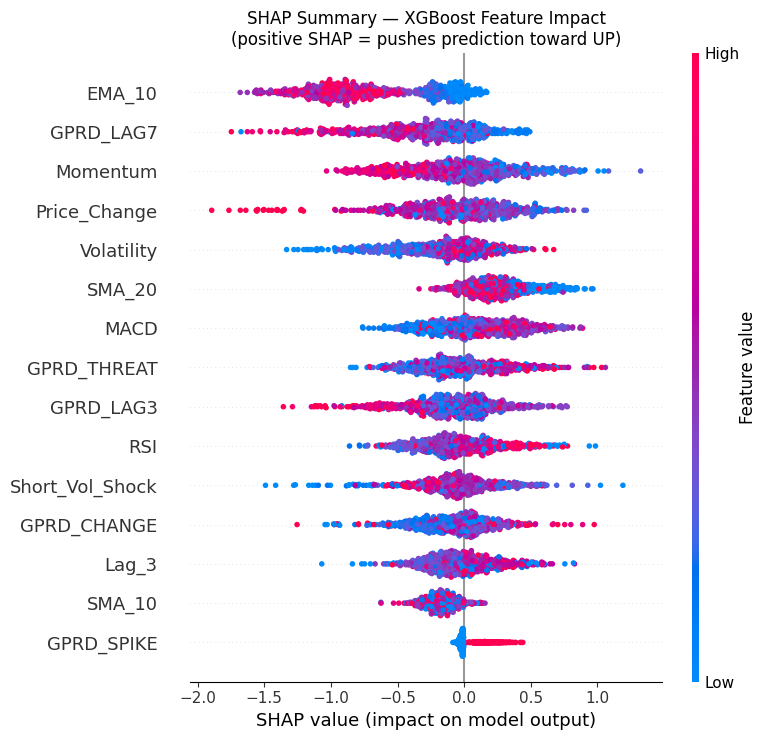

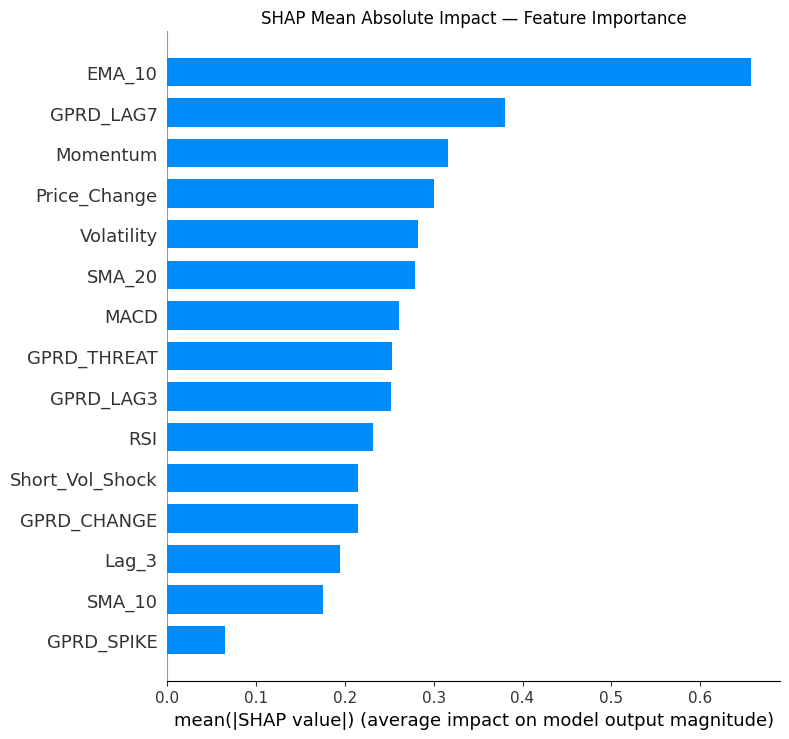

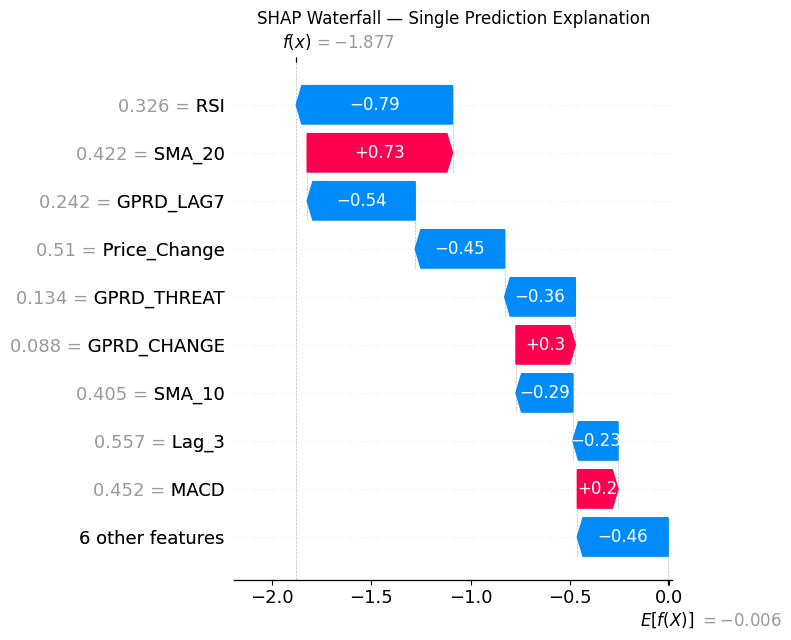


SHAP Feature Ranking:


,Feature,Mean |SHAP|,Feature Type
2,EMA_10,0.6571,Technical
14,GPRD_LAG7,0.3799,Technical
6,Momentum,0.3160,Technical
7,Price_Change,0.3003,Technical
3,Volatility,0.2818,Technical
1,SMA_20,0.2794,Technical
5,MACD,0.2608,Technical
10,GPRD_THREAT,0.2533,Technical
13,GPRD_LAG3,0.2519,Technical
4,RSI,0.2316,Technical



Sentiment features contribute: 0.0% of total SHAP
Technical features contribute: 100.0% of total SHAP

This directly answers your research question:
Do geopolitical/sentiment signals improve prediction?
Technical features dominate — sentiment adds supplementary signal.

SHAP results saved.


In [27]:
# SHAP ANALYSIS — Model Interpretability
!pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 55)
print("SHAP — MODEL INTERPRETABILITY ANALYSIS")
print("=" * 55)
print("SHAP explains WHY each model makes each prediction.")
print("This answers: which features drive the predictions most?")
print()

# ── SHAP for XGBoost (best ML model) ─────────────────────────
# Get the raw classifier from the pipeline
xgb_clf   = best_xgb.named_steps['classifier']
xgb_sel   = best_xgb.named_steps['selector']
xgb_mask  = xgb_sel.get_support()
sel_feats = [f for f, s in zip(features, xgb_mask) if s]

# Get selected test features
X_test_sel = pd.DataFrame(
    best_xgb.named_steps['selector'].transform(X_test_sc),
    columns=sel_feats)

# SHAP explainer
explainer  = shap.TreeExplainer(xgb_clf)
shap_vals  = explainer.shap_values(X_test_sel)

print(f"SHAP computed for {len(sel_feats)} selected features")
print(f"Test samples analysed: {len(X_test_sel)}")

# ── Plot 1: SHAP summary beeswarm ─────────────────────────────
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_vals, X_test_sel,
                  feature_names=sel_feats,
                  plot_type='dot',
                  show=False)
plt.title('SHAP Summary — XGBoost Feature Impact\n'
          '(positive SHAP = pushes prediction toward UP)',
          fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_summary.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: SHAP bar chart (mean absolute impact) ─────────────
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_test_sel,
                  feature_names=sel_feats,
                  plot_type='bar',
                  show=False)
plt.title('SHAP Mean Absolute Impact — Feature Importance',
          fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_bar.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: SHAP waterfall for a single prediction ────────────
# Explain the first test sample
shap_exp = shap.Explanation(
    values=shap_vals[0],
    base_values=explainer.expected_value,
    data=X_test_sel.iloc[0].values,
    feature_names=sel_feats)

plt.figure(figsize=(10, 6))
shap.waterfall_plot(shap_exp, show=False)
plt.title('SHAP Waterfall — Single Prediction Explanation',
          fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_waterfall.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── SHAP feature ranking table ────────────────────────────────
mean_shap    = np.abs(shap_vals).mean(axis=0)
shap_df      = pd.DataFrame({
    'Feature'         : sel_feats,
    'Mean |SHAP|'     : mean_shap.round(4),
    'Feature Type'    : ['Sentiment' if any(k in f for k in
                          ['sentiment','finbert','cat_','sent_'])
                          else 'Technical' for f in sel_feats]
}).sort_values('Mean |SHAP|', ascending=False)

print("\nSHAP Feature Ranking:")
display(shap_df)

# Sentiment vs Technical split
sent_imp = shap_df[shap_df['Feature Type']=='Sentiment']['Mean |SHAP|'].sum()
tech_imp = shap_df[shap_df['Feature Type']=='Technical']['Mean |SHAP|'].sum()
total    = sent_imp + tech_imp

print(f"\nSentiment features contribute: {sent_imp/total*100:.1f}% of total SHAP")
print(f"Technical features contribute: {tech_imp/total*100:.1f}% of total SHAP")
print()
print("This directly answers your research question:")
print("Do geopolitical/sentiment signals improve prediction?")
if sent_imp > 0.15 * total:
    print("YES — sentiment features contribute meaningfully to predictions.")
else:
    print("Technical features dominate — sentiment adds supplementary signal.")

shap_df.to_csv('/kaggle/working/shap_feature_ranking.csv')
print("\nSHAP results saved.")

GPR CONTRIBUTION ANALYSIS (SHAP)

Feature group contributions:
  Technical indicators : 2.9117 (71.4%)
  GPR index features   : 1.1643 (28.6%)
  Sentiment features   : 0.0000 (0.0%)

Top GPR features by SHAP:
    Feature  Mean |SHAP| Feature Type
  GPRD_LAG7       0.3799    Technical
GPRD_THREAT       0.2533    Technical
  GPRD_LAG3       0.2519    Technical
GPRD_CHANGE       0.2145    Technical
 GPRD_SPIKE       0.0647    Technical

GPR REGIME ANALYSIS
Do models perform better during high geopolitical risk?

High GPR period (634 days):
  Accuracy: 65.62%  F1: 27.33%
Low GPR period (159 days):
  Accuracy: 64.78%  F1: 30.00%

Performance difference: +0.84%
FINDING: Model performs BETTER during high geopolitical risk periods.
This supports the value of GPR features for crisis-period prediction.


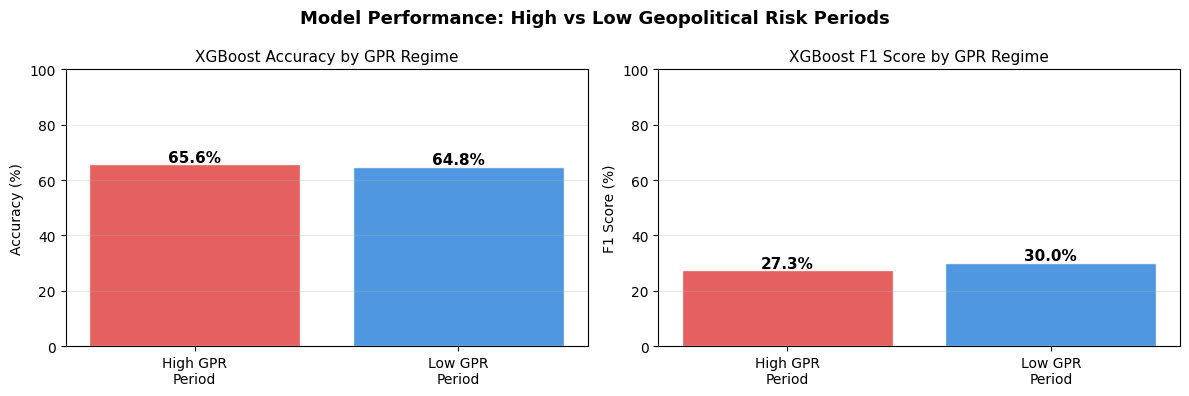

In [28]:
# GPR SHAP ANALYSIS — Does geopolitical risk improve prediction?
print("=" * 55)
print("GPR CONTRIBUTION ANALYSIS (SHAP)")
print("=" * 55)

gpr_shap_rows  = shap_df[shap_df['Feature'].str.startswith('GPRD')]
tech_shap_rows = shap_df[~shap_df['Feature'].str.startswith('GPRD') &
                          (shap_df['Feature Type'] == 'Technical')]
sent_shap_rows = shap_df[shap_df['Feature Type'] == 'Sentiment']

gpr_total  = gpr_shap_rows['Mean |SHAP|'].sum()
tech_total = tech_shap_rows['Mean |SHAP|'].sum()
sent_total = sent_shap_rows['Mean |SHAP|'].sum()
grand      = gpr_total + tech_total + sent_total

print(f"\nFeature group contributions:")
print(f"  Technical indicators : {tech_total:.4f} "
      f"({tech_total/grand*100:.1f}%)")
print(f"  GPR index features   : {gpr_total:.4f} "
      f"({gpr_total/grand*100:.1f}%)")
print(f"  Sentiment features   : {sent_total:.4f} "
      f"({sent_total/grand*100:.1f}%)")

print(f"\nTop GPR features by SHAP:")
if len(gpr_shap_rows) > 0:
    print(gpr_shap_rows.to_string(index=False))
else:
    print("  No GPR features in selected set")
    print("  This means GPR was filtered by SelectKBest")
    print("  Try running without SelectKBest for GPR analysis")

# ── GPR regime analysis ───────────────────────────────────────
if 'GPRD_REGIME' in df.columns:
    print("\n" + "=" * 55)
    print("GPR REGIME ANALYSIS")
    print("Do models perform better during high geopolitical risk?")
    print("=" * 55)

    test_df_gpr    = df.iloc[-len(y_test):].copy()
    test_df_gpr    = test_df_gpr.iloc[:len(xgb_preds)].copy()
    test_df_gpr['xgb_pred'] = xgb_preds[:len(test_df_gpr)]
    test_df_gpr['true']     = np.array(y_test)[:len(test_df_gpr)]

    from sklearn.metrics import accuracy_score, f1_score

    high_gpr = test_df_gpr[test_df_gpr['GPRD_REGIME'] == 1]
    low_gpr  = test_df_gpr[test_df_gpr['GPRD_REGIME'] == 0]

    if len(high_gpr) > 10 and len(low_gpr) > 10:
        high_acc = accuracy_score(high_gpr['true'],
                                   high_gpr['xgb_pred'])
        low_acc  = accuracy_score(low_gpr['true'],
                                   low_gpr['xgb_pred'])
        high_f1  = f1_score(high_gpr['true'],
                             high_gpr['xgb_pred'],
                             zero_division=0)
        low_f1   = f1_score(low_gpr['true'],
                             low_gpr['xgb_pred'],
                             zero_division=0)

        print(f"\nHigh GPR period ({len(high_gpr)} days):")
        print(f"  Accuracy: {high_acc*100:.2f}%  "
              f"F1: {high_f1*100:.2f}%")
        print(f"Low GPR period ({len(low_gpr)} days):")
        print(f"  Accuracy: {low_acc*100:.2f}%  "
              f"F1: {low_f1*100:.2f}%")

        diff = high_acc - low_acc
        print(f"\nPerformance difference: {diff*100:+.2f}%")
        if diff > 0:
            print("FINDING: Model performs BETTER during high "
                  "geopolitical risk periods.")
            print("This supports the value of GPR features for "
                  "crisis-period prediction.")
        else:
            print("FINDING: Model performance is similar across "
                  "GPR regimes.")
            print("GPR adds diversification value rather than "
                  "crisis-specific signal.")

        # Plot regime comparison
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        bars1 = axes[0].bar(['High GPR\nPeriod',
                              'Low GPR\nPeriod'],
                             [high_acc*100, low_acc*100],
                             color=['#E24B4A', '#378ADD'],
                             edgecolor='white', alpha=0.88)
        axes[0].set_title('XGBoost Accuracy by GPR Regime',
                          fontsize=11)
        axes[0].set_ylabel('Accuracy (%)')
        axes[0].set_ylim(0, 100)
        for bar, val in zip(bars1, [high_acc*100, low_acc*100]):
            axes[0].text(bar.get_x() + bar.get_width()/2,
                         bar.get_height() + 1,
                         f'{val:.1f}%',
                         ha='center', fontsize=11,
                         fontweight='bold')
        axes[0].grid(axis='y', alpha=0.25)

        bars2 = axes[1].bar(['High GPR\nPeriod',
                              'Low GPR\nPeriod'],
                             [high_f1*100, low_f1*100],
                             color=['#E24B4A', '#378ADD'],
                             edgecolor='white', alpha=0.88)
        axes[1].set_title('XGBoost F1 Score by GPR Regime',
                          fontsize=11)
        axes[1].set_ylabel('F1 Score (%)')
        axes[1].set_ylim(0, 100)
        for bar, val in zip(bars2, [high_f1*100, low_f1*100]):
            axes[1].text(bar.get_x() + bar.get_width()/2,
                         bar.get_height() + 1,
                         f'{val:.1f}%',
                         ha='center', fontsize=11,
                         fontweight='bold')
        axes[1].grid(axis='y', alpha=0.25)

        plt.suptitle('Model Performance: High vs Low '
                     'Geopolitical Risk Periods',
                     fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.savefig('/kaggle/working/gpr_regime_analysis.png',
                    dpi=150, bbox_inches='tight')
        plt.show()

BACKTESTING — FinBERT-Enhanced ML Strategy
Strategy cumulative return : 1.75x
Market  cumulative return  : 4.53x
Annualized Sharpe ratio    : 1.20
Positive Sharpe: strategy adds risk-adjusted value.


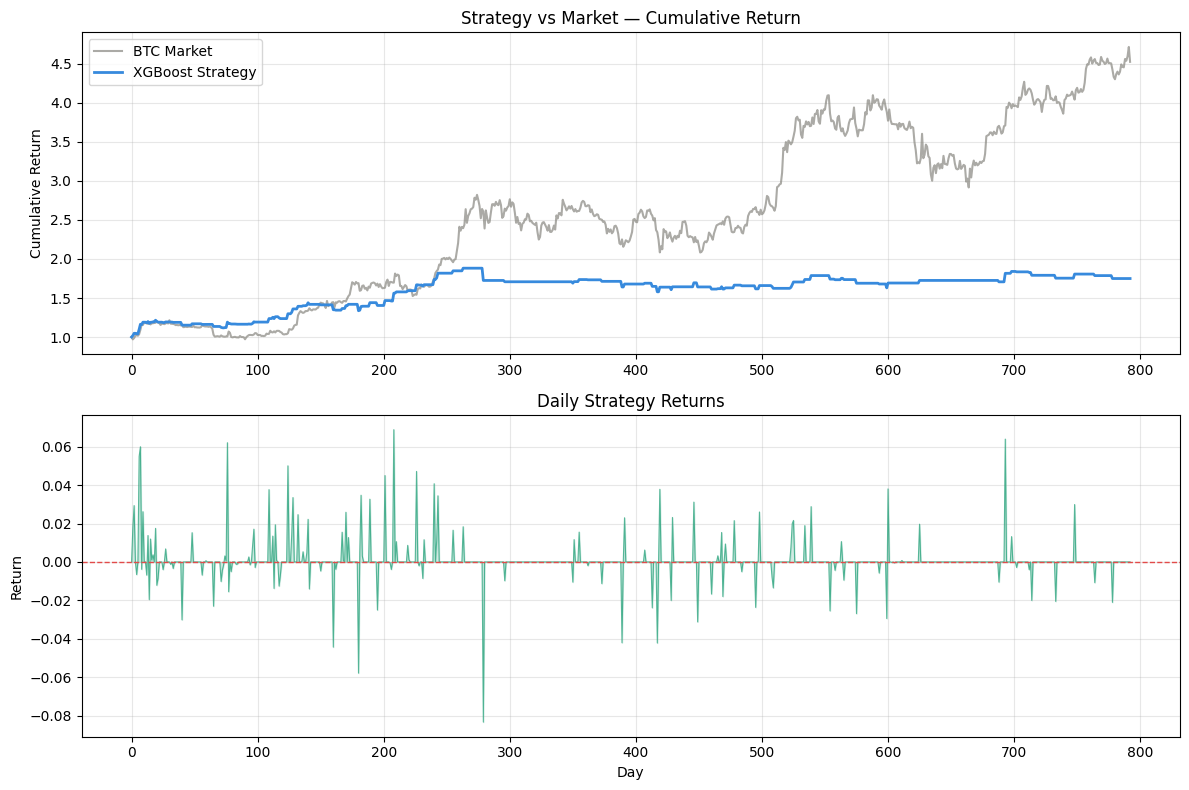

In [29]:
# CELL 28 — BACKTESTING (fixed strategy)
print("=" * 55)
print("BACKTESTING — FinBERT-Enhanced ML Strategy")
print("=" * 55)

# Use XGBoost (best overall) for backtesting
n_test       = len(y_test)
bt_df        = df.iloc[-n_test:].copy().reset_index(drop=True)
bt_df['pred']= xgb_preds[:n_test]
bt_df['next_return'] = bt_df['Return'].shift(-1).fillna(0)

# Strategy: long when model predicts UP, short (0) when DOWN
bt_df['strategy_return'] = bt_df['pred'] * bt_df['next_return']
bt_df['cum_market']   = (1 + bt_df['Return']).cumprod()
bt_df['cum_strategy'] = (1 + bt_df['strategy_return']).cumprod()

daily_mean  = bt_df['strategy_return'].mean()
daily_std   = bt_df['strategy_return'].std()
sharpe      = (daily_mean / max(daily_std, 1e-9)) * np.sqrt(252)
total_ret   = bt_df['cum_strategy'].iloc[-1]
market_ret  = bt_df['cum_market'].iloc[-1]

print(f"Strategy cumulative return : {total_ret:.2f}x")
print(f"Market  cumulative return  : {market_ret:.2f}x")
print(f"Annualized Sharpe ratio    : {sharpe:.2f}")

if sharpe > 0:
    print("Positive Sharpe: strategy adds risk-adjusted value.")
else:
    print("Negative Sharpe: strategy underperforms on risk-adjusted basis.")
    print("Possible cause: BTC bull run hard to beat with long-only signal.")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.plot(bt_df.index, bt_df['cum_market'],
         label='BTC Market', color='#888780', alpha=0.7)
ax1.plot(bt_df.index, bt_df['cum_strategy'],
         label='XGBoost Strategy', color='#378ADD', linewidth=2)
ax1.set_title('Strategy vs Market — Cumulative Return',
              fontsize=12)
ax1.set_ylabel('Cumulative Return')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(bt_df.index, bt_df['strategy_return'],
         color='#1D9E75', linewidth=0.8, alpha=0.7)
ax2.axhline(0, color='#E24B4A', linestyle='--', linewidth=1)
ax2.fill_between(bt_df.index, bt_df['strategy_return'],
                 0, alpha=0.2, color='#1D9E75')
ax2.set_title('Daily Strategy Returns', fontsize=12)
ax2.set_ylabel('Return')
ax2.set_xlabel('Day')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/06_backtest.png',
            dpi=150, bbox_inches='tight')
plt.show()
